# Adaptive CASTNet — Full Research Experiment on PEMS04 and PEMS08

## Traffic Flow Forecasting with Dynamic Graph Sampling Attention

This notebook is the **full-experiment version** of the earlier Adaptive CASTNet prototype.

### What changed from the old notebook?

- METR-LA is removed from the main experiment.
- We evaluate on **PEMS04 and PEMS08**, two standard PeMS traffic-flow benchmarks.
- PEMS04 has **307 sensors / 16,992 time steps**.
- PEMS08 has **170 sensors / 17,856 time steps**.
- Both are sampled every **5 minutes** and contain **flow, speed, occupancy** channels.
- We forecast the **traffic-flow channel**.
- We use **all sensors** for each dataset.
- We use a chronological **60% / 20% / 20% train/validation/test split**, a common protocol for these datasets.
- We use **12 historical steps → 12 future steps**, i.e. 60 minutes of history to predict the next 60 minutes.
- Training uses early stopping and validation-based model selection.
- The notebook evaluates 15-, 30-, and 60-minute horizons.
- We compare LSTM, GCN-LSTM, Hierarchical ST-Transformer, CASTNet-Lite, and the proposed Adaptive CASTNet.
- We include ablation, congestion analysis, parameter count, inference time, plots, and result export.

### Important research note

This is a **research implementation inspired by CASTNet and the hierarchical spatio-temporal Transformer paper**, not a claim that this notebook reproduces the authors' exact source code.

PEMS04/PEMS08 are established PeMS benchmarks rather than newly collected 2026 data. They are, however, newer/different benchmarks than the METR-LA benchmark used in the previous prototype and are widely used for current traffic-forecasting comparisons. PEMS04 contains 307 sensors and PEMS08 contains 170 sensors. citeturn0search1turn1search0


## Research question

> **Does adapting the sensor graph to the current traffic state improve traffic-flow forecasting compared with static graph-based spatio-temporal models?**

### Base paper

**CASTNet — Convolution Augmented Graph Sampling Transformer Network for Traffic Flow Forecasting.**

### Supporting paper

**Hierarchical Spatio–Temporal Graph Convolutional Networks and Transformer Network for Traffic Flow Forecasting.**

### Proposed contribution

We add a **traffic-state-dependent dynamic graph learner** to a CASTNet-inspired architecture.

```text
Traffic history
      ↓
Graph convolution
      ↓
Temporal convolution
      ↓
Dynamic graph learner
      ↓
Traffic-state-dependent graph
      ↓
Top-k sampled graph attention
      ↓
Feature refinement
      ↓
Traffic-flow forecast
```


In [ ]:
# ============================================================
# 1. INSTALL + IMPORTS
# ============================================================
!pip -q install numpy pandas scipy scikit-learn matplotlib tqdm h5py

import os
import random
import math
import time
import json
import csv
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device :", DEVICE)

if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))
else:
    print("WARNING: You are on CPU. Switch Colab to a GPU runtime.")


PyTorch: 2.11.0+cu128
Device : cuda
GPU    : Tesla T4


# 2. Dataset choice

## PEMS04
- 307 sensors
- 16,992 time steps
- 5-minute interval
- flow + speed + occupancy
- January–February 2018

## PEMS08
- 170 sensors
- 17,856 time steps
- 5-minute interval
- flow + speed + occupancy
- July–August period in the public benchmark

The public Zenodo archive provides the NPZ traffic files and graph CSV files used by many implementations. citeturn1search0turn3search0

The graph CSV represents directed sensor connections with `from`, `to`, and `cost` fields. We turn those road-distance relationships into a symmetric weighted graph for our GNN. citeturn3search6


In [ ]:
# ============================================================
# 3. DATASET DOWNLOAD
# ============================================================
DATA_ROOT = "/content/pems_data"
os.makedirs(DATA_ROOT, exist_ok=True)

DATA_URLS = {
    "PEMS04": {
        "npz": "https://zenodo.org/records/7816008/files/PEMS04.npz?download=1",
        "csv": "https://zenodo.org/records/7816008/files/PEMS04.csv?download=1",
    },
    "PEMS08": {
        "npz": "https://zenodo.org/records/7816008/files/PEMS08.npz?download=1",
        "csv": "https://zenodo.org/records/7816008/files/PEMS08.csv?download=1",
    }
}

def download_file(url, path):
    if os.path.exists(path) and os.path.getsize(path) > 1024:
        print("Already exists:", path)
        return

    print("Downloading:", os.path.basename(path))

    try:
        urllib.request.urlretrieve(url, path)
    except Exception as e:
        if os.path.exists(path):
            os.remove(path)
        raise RuntimeError(
            f"Download failed for {url}. "
            f"Open the Zenodo dataset page and download the file manually if necessary. "
            f"Original error: {e}"
        )

for ds_name, urls in DATA_URLS.items():

    ds_dir = os.path.join(
        DATA_ROOT,
        ds_name
    )

    os.makedirs(
        ds_dir,
        exist_ok=True
    )

    download_file(
        urls["npz"],
        os.path.join(
            ds_dir,
            f"{ds_name}.npz"
        )
    )

    download_file(
        urls["csv"],
        os.path.join(
            ds_dir,
            f"{ds_name}.csv"
        )
    )

print("Dataset files ready.")


Downloading: PEMS04.npz
Downloading: PEMS04.csv
Downloading: PEMS08.npz
Downloading: PEMS08.csv
Dataset files ready.


In [ ]:
# ============================================================
# 4. DATASET INSPECTION
# ============================================================
EXPECTED = {
    "PEMS04": {"nodes": 307},
    "PEMS08": {"nodes": 170}
}

for name in ["PEMS04", "PEMS08"]:

    npz_path = os.path.join(
        DATA_ROOT,
        name,
        f"{name}.npz"
    )

    data = np.load(
        npz_path,
        allow_pickle=True
    )

    print("\n", name)
    print("NPZ keys:", data.files)

    arr = data["data"]

    print("Raw shape:", arr.shape)
    print("Expected nodes:", EXPECTED[name]["nodes"])
    print("Features:", arr.shape[-1])



 PEMS04
NPZ keys: ['data']
Raw shape: (16992, 307, 3)
Expected nodes: 307
Features: 3

 PEMS08
NPZ keys: ['data']
Raw shape: (17856, 170, 3)
Expected nodes: 170
Features: 3


# 3. Experimental protocol

We follow a common protocol for PEMS04/PEMS08:

```text
60% → Train
20% → Validation
20% → Test
```

The split is **chronological**. We never shuffle the full time series before splitting, which prevents future information from leaking into training.

Input:

```text
12 × 5 minutes = 60 minutes
```

Output:

```text
12 × 5 minutes = next 60 minutes
```

The target is **flow**, i.e. channel 0 of the PEMS tensors. PEMS04/PEMS08 contain flow, occupancy and speed in the public benchmark format. citeturn3search0turn3search6


In [ ]:
# ============================================================
# 5. CONFIGURATION
# ============================================================

INPUT_STEPS = 12
FORECAST_HORIZON = 12

HIDDEN = 64
HEADS = 4
TOPK = 8
DROPOUT = 0.10

BATCH_SIZE = 16

# Full training:
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

NUM_WORKERS = 2

# Final evaluation datasets
DATASETS = ["PEMS04", "PEMS08"]

# For a rigorous final study, you can set this to:
# [42, 123, 2026]
FINAL_SEEDS = [42]

print("Configuration loaded.")


Configuration loaded.


In [ ]:
# ============================================================
# 6. LOAD GRAPH
# ============================================================
def build_adjacency_from_csv(
    csv_path,
    n_nodes
):

    edge_df = pd.read_csv(
        csv_path
    )

    # Standard PeMS graph format:
    # from,to,cost
    required = {"from", "to", "cost"}

    if not required.issubset(
        set(edge_df.columns)
    ):
        raise ValueError(
            f"Expected columns {required}, "
            f"found {list(edge_df.columns)}"
        )

    dist = np.full(
        (n_nodes, n_nodes),
        np.inf,
        dtype=np.float32
    )

    for _, row in edge_df.iterrows():

        i = int(row["from"])
        j = int(row["to"])
        cost = float(row["cost"])

        if 0 <= i < n_nodes and 0 <= j < n_nodes:
            dist[i,j] = cost

    finite = dist[
        np.isfinite(dist)
    ]

    sigma = (
        finite.std()
        + 1e-6
    )

    # Gaussian distance kernel
    A = np.exp(
        -np.square(
            dist / sigma
        )
    )

    A[
        ~np.isfinite(A)
    ] = 0.0

    # Make road graph undirected for our message-passing layer.
    A = np.maximum(
        A,
        A.T
    )

    # Remove extremely weak edges.
    A[A < 0.05] = 0.0

    # Self-loop.
    np.fill_diagonal(
        A,
        1.0
    )

    # Symmetric normalization.
    degree = A.sum(
        axis=1
    )

    inv_sqrt = 1.0 / np.sqrt(
        np.maximum(
            degree,
            1e-8
        )
    )

    A_norm = (
        inv_sqrt[:,None]
        * A
        * inv_sqrt[None,:]
    )

    return A.astype(np.float32), A_norm.astype(np.float32)


GRAPH_INFO = {}

for name in DATASETS:

    n = EXPECTED[name]["nodes"]

    csv_path = os.path.join(
        DATA_ROOT,
        name,
        f"{name}.csv"
    )

    A_raw, A_norm = build_adjacency_from_csv(
        csv_path,
        n
    )

    GRAPH_INFO[name] = {
        "A_raw": A_raw,
        "A_norm": A_norm
    }

    print(
        name,
        "| nodes:", n,
        "| edges:", np.count_nonzero(A_raw)
    )


PEMS04 | nodes: 307 | edges: 859
PEMS08 | nodes: 170 | edges: 592


In [ ]:
# ============================================================
# 7. DATA PREPARATION
# ============================================================
def prepare_dataset(
    name
):

    npz_path = os.path.join(
        DATA_ROOT,
        name,
        f"{name}.npz"
    )

    raw = np.load(
        npz_path,
        allow_pickle=True
    )["data"].astype(
        np.float32
    )

    # raw = [time, nodes, features]
    #
    # Channel 0 = flow
    # Channel 1/2 = other traffic measurements
    flow = raw[:,:,0]

    # Replace invalid values.
    flow = np.nan_to_num(
        flow,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    T, N = flow.shape

    # --------------------------------------------------------
    # Chronological 60/20/20 split.
    # --------------------------------------------------------
    train_end = int(
        T * 0.60
    )

    val_end = int(
        T * 0.80
    )

    # Z-score using TRAINING data only.
    train_values = flow[
        :train_end
    ]

    mean = float(
        train_values.mean()
    )

    std = float(
        train_values.std()
        + 1e-6
    )

    normalized = (
        flow - mean
    ) / std

    print(
        f"{name}:",
        f"T={T}, N={N},",
        f"mean={mean:.4f},",
        f"std={std:.4f}"
    )

    return {
        "raw": flow,
        "normalized": normalized.astype(np.float32),
        "train_end": train_end,
        "val_end": val_end,
        "mean": mean,
        "std": std,
        "nodes": N
    }


DATA_INFO = {
    name: prepare_dataset(name)
    for name in DATASETS
}


PEMS04: T=16992, N=307, mean=207.2369, std=156.4841
PEMS08: T=17856, N=170, mean=229.6613, std=145.6415


In [ ]:
# ============================================================
# 8. WINDOW DATASET
# ============================================================
class TrafficWindowDataset(Dataset):

    def __init__(
        self,
        data,
        start,
        end,
        input_steps=12,
        horizon=12
    ):

        self.data = data
        self.input_steps = input_steps
        self.horizon = horizon

        # Last valid starting index.
        last_start = (
            end
            - input_steps
            - horizon
            + 1
        )

        if last_start <= start:
            raise ValueError(
                "Not enough data for this split."
            )

        self.starts = np.arange(
            start,
            last_start
        )

    def __len__(self):
        return len(
            self.starts
        )

    def __getitem__(
        self,
        index
    ):

        s = int(
            self.starts[index]
        )

        x = self.data[
            s:
            s + self.input_steps
        ]

        y = self.data[
            s + self.input_steps:
            s + self.input_steps + self.horizon
        ]

        # Add feature/channel dimension.
        x = x[...,None]
        y = y[...,None]

        return (
            torch.from_numpy(
                x.astype(np.float32)
            ),
            torch.from_numpy(
                y.astype(np.float32)
            )
        )


def make_loaders(
    name
):

    info = DATA_INFO[name]

    data = info["normalized"]

    T = data.shape[0]

    train_end = info["train_end"]
    val_end = info["val_end"]

    train_ds = TrafficWindowDataset(
        data,
        0,
        train_end,
        INPUT_STEPS,
        FORECAST_HORIZON
    )

    val_ds = TrafficWindowDataset(
        data,
        train_end,
        val_end,
        INPUT_STEPS,
        FORECAST_HORIZON
    )

    test_ds = TrafficWindowDataset(
        data,
        val_end,
        T,
        INPUT_STEPS,
        FORECAST_HORIZON
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type=="cuda"),
        persistent_workers=(NUM_WORKERS > 0)
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type=="cuda"),
        persistent_workers=(NUM_WORKERS > 0)
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type=="cuda"),
        persistent_workers=(NUM_WORKERS > 0)
    )

    return (
        train_loader,
        val_loader,
        test_loader
    )


LOADERS = {
    name: make_loaders(name)
    for name in DATASETS
}

for name, loaders in LOADERS.items():

    print(
        name,
        "| train:", len(loaders[0].dataset),
        "| val:", len(loaders[1].dataset),
        "| test:", len(loaders[2].dataset)
    )


PEMS04 | train: 10172 | val: 3375 | test: 3376
PEMS08 | train: 10690 | val: 3548 | test: 3549


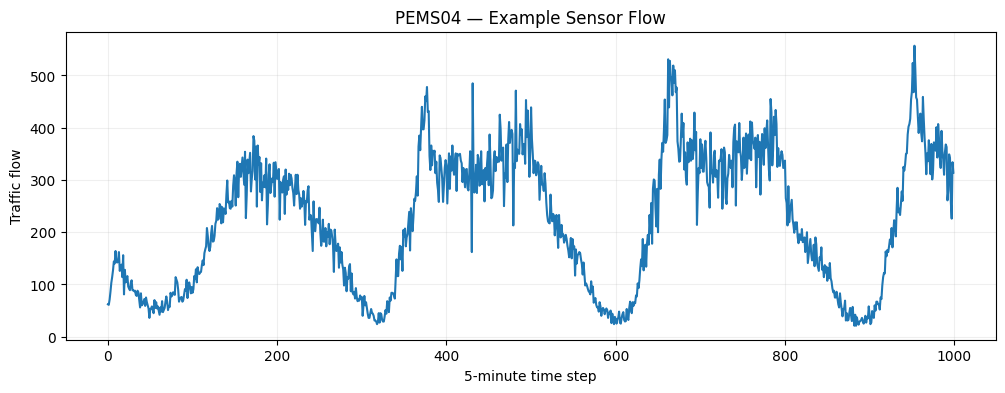

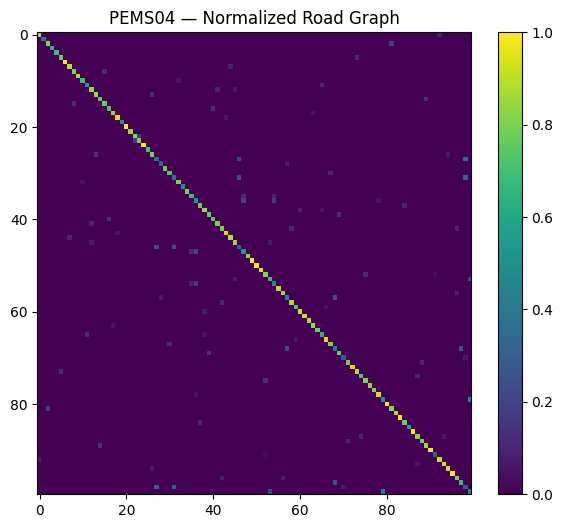

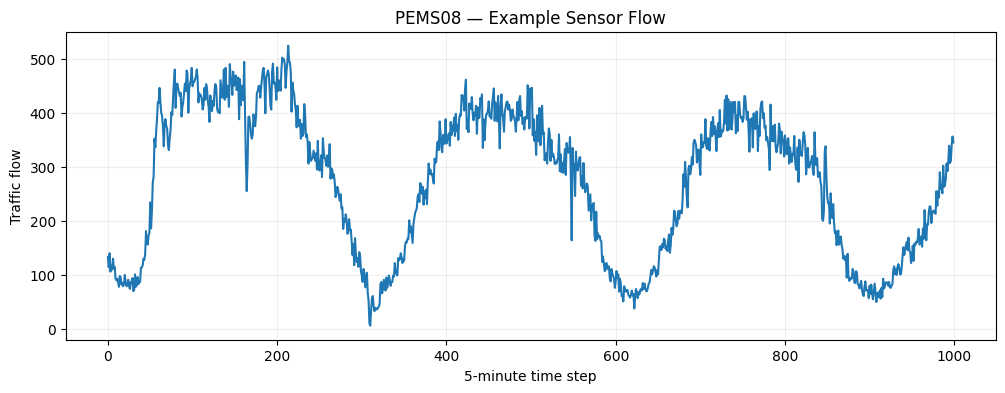

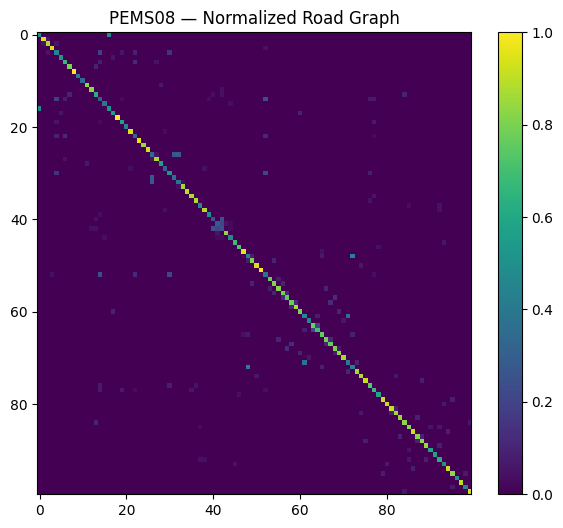

In [ ]:
# ============================================================
# 9. BASIC DATA VISUALIZATION
# ============================================================
for name in DATASETS:

    raw = DATA_INFO[name]["raw"]

    plt.figure(figsize=(12,4))

    plt.plot(
        raw[:1000,0]
    )

    plt.title(
        f"{name} — Example Sensor Flow"
    )

    plt.xlabel(
        "5-minute time step"
    )

    plt.ylabel(
        "Traffic flow"
    )

    plt.grid(
        alpha=0.2
    )

    plt.show()

    plt.figure(figsize=(7,6))

    plt.imshow(
        GRAPH_INFO[name]["A_norm"][
            :min(100,raw.shape[1]),
            :min(100,raw.shape[1])
        ],
        aspect="auto"
    )

    plt.title(
        f"{name} — Normalized Road Graph"
    )

    plt.colorbar()

    plt.show()


# 4. Model components

We use the same core modeling idea across the experiments:

### Graph Convolution
Captures local spatial information from connected traffic sensors.

### Temporal Convolution
Captures short-term patterns in the historical traffic sequence.

### Transformer-style attention
Learns which graph neighbors are important.

### Dynamic Graph Learner
Our proposed component. It changes the graph weights according to the current hidden traffic state.

### Top-k sampling
Only the strongest graph neighbors are used by sampled attention.


In [ ]:
# ============================================================
# 10. GRAPH CONVOLUTION
# ============================================================
class GraphConv(nn.Module):

    def __init__(
        self,
        in_dim,
        out_dim
    ):
        super().__init__()

        self.linear = nn.Linear(
            in_dim,
            out_dim
        )

    def forward(
        self,
        x,
        A
    ):

        # x = [B,T,N,F]
        #
        # A = [N,N]

        aggregated = torch.einsum(
            "ij,btjf->btif",
            A,
            x
        )

        return self.linear(
            aggregated
        )


class TemporalConv(nn.Module):

    def __init__(
        self,
        channels,
        kernel_size=3
    ):
        super().__init__()

        self.conv = nn.Conv1d(
            channels,
            channels,
            kernel_size,
            padding=kernel_size//2
        )

        self.norm = nn.LayerNorm(
            channels
        )

    def forward(
        self,
        x
    ):

        # x = [B,T,N,C]

        B,T,N,C = x.shape

        z = x.permute(
            0,2,3,1
        ).reshape(
            B*N,
            C,
            T
        )

        z = self.conv(z)

        z = z.transpose(
            1,2
        )

        z = z.reshape(
            B,
            N,
            T,
            C
        ).permute(
            0,
            2,
            1,
            3
        )

        return self.norm(
            z
        )


class FeedForward(nn.Module):

    def __init__(
        self,
        dim,
        dropout=0.1
    ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim, dim*4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim*4, dim)
        )

    def forward(self,x):
        return self.net(x)


In [ ]:
# ============================================================
# 11. BASELINE — LSTM
# ============================================================
class LSTMModel(nn.Module):

    def __init__(
        self,
        n_nodes,
        hidden=64,
        horizon=12
    ):
        super().__init__()

        self.n_nodes = n_nodes
        self.horizon = horizon

        self.lstm = nn.LSTM(
            input_size=n_nodes,
            hidden_size=hidden,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden,
            horizon*n_nodes
        )

    def forward(
        self,
        x
    ):

        x = x.squeeze(-1)

        h,_ = self.lstm(
            x
        )

        out = self.fc(
            h[:,-1]
        )

        return out.view(
            x.size(0),
            self.horizon,
            self.n_nodes,
            1
        )


In [ ]:
# ============================================================
# 12. BASELINE — GCN + LSTM
# ============================================================
class GCNLSTM(nn.Module):

    def __init__(
        self,
        hidden=64,
        horizon=12
    ):
        super().__init__()

        self.gc = GraphConv(
            1,
            hidden
        )

        self.lstm = nn.LSTM(
            hidden,
            hidden,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden,
            horizon
        )

        self.horizon = horizon

    def forward(
        self,
        x,
        A
    ):

        z = F.relu(
            self.gc(x,A)
        )

        B,T,N,H = z.shape

        # Each sensor gets its own temporal sequence.
        z = z.permute(
            0,
            2,
            1,
            3
        ).reshape(
            B*N,
            T,
            H
        )

        h,_ = self.lstm(
            z
        )

        out = self.fc(
            h[:,-1]
        )

        out = out.view(
            B,
            N,
            self.horizon
        )

        return out.permute(
            0,
            2,
            1
        ).unsqueeze(-1)


In [ ]:
# ============================================================
# 13. HIERARCHICAL SPATIO-TEMPORAL TRANSFORMER
# ============================================================
class HierarchicalSTTransformer(nn.Module):

    def __init__(
        self,
        hidden=64,
        heads=4,
        horizon=12,
        dropout=0.1
    ):
        super().__init__()

        self.gc = GraphConv(
            1,
            hidden
        )

        self.temporal_conv = TemporalConv(
            hidden
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden,
            nhead=heads,
            dim_feedforward=hidden*4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.fc = nn.Linear(
            hidden,
            horizon
        )

    def forward(
        self,
        x,
        A
    ):

        z = F.relu(
            self.gc(x,A)
        )

        z = z + self.temporal_conv(
            z
        )

        B,T,N,H = z.shape

        # Temporal attention independently for each sensor.
        seq = z.permute(
            0,
            2,
            1,
            3
        ).reshape(
            B*N,
            T,
            H
        )

        seq = self.transformer(
            seq
        )

        last = seq[:,-1].reshape(
            B,
            N,
            H
        )

        out = self.fc(
            last
        )

        return out.permute(
            0,
            2,
            1
        ).unsqueeze(-1)


# 5. Efficient sampled graph attention

The first prototype used an `N × N × hidden` expansion during neighbor gathering. That becomes unnecessarily expensive at 307 nodes.

The implementation below uses **batched advanced indexing** so that only the selected top-k neighbors are materialized.

This matters for the full PEMS04 experiment.


In [ ]:
# ============================================================
# 14. MEMORY-EFFICIENT SAMPLED GRAPH ATTENTION
# ============================================================
class SampledGraphAttention(nn.Module):

    def __init__(
        self,
        dim,
        heads=4,
        topk=8,
        dropout=0.1
    ):
        super().__init__()

        assert dim % heads == 0

        self.dim = dim
        self.heads = heads
        self.head_dim = dim // heads
        self.topk = topk

        self.q = nn.Linear(
            dim,
            dim,
            bias=False
        )

        self.k = nn.Linear(
            dim,
            dim,
            bias=False
        )

        self.v = nn.Linear(
            dim,
            dim,
            bias=False
        )

        self.out = nn.Linear(
            dim,
            dim
        )

        self.drop = nn.Dropout(
            dropout
        )

    def forward(
        self,
        x,
        A
    ):

        # x = [B,N,C]
        B,N,C = x.shape

        k = min(
            self.topk,
            N
        )

        Q = self.q(x).view(
            B,
            N,
            self.heads,
            self.head_dim
        ).transpose(
            1,2
        )

        K = self.k(x).view(
            B,
            N,
            self.heads,
            self.head_dim
        )

        V = self.v(x).view(
            B,
            N,
            self.heads,
            self.head_dim
        )

        # ----------------------------------------------------
        # A can be:
        # [N,N]      static graph
        # [B,N,N]    dynamic graph
        # ----------------------------------------------------
        if A.dim() == 2:

            edge_values, indices = torch.topk(
                A,
                k=k,
                dim=-1
            )

            indices = indices.unsqueeze(
                0
            ).expand(
                B,
                N,
                k
            )

            edge_values = edge_values.unsqueeze(
                0
            ).expand(
                B,
                N,
                k
            )

        else:

            edge_values, indices = torch.topk(
                A,
                k=k,
                dim=-1
            )

        # ----------------------------------------------------
        # Efficient neighbor gather
        # ----------------------------------------------------
        batch_index = torch.arange(
            B,
            device=x.device
        ).view(
            B,
            1,
            1
        )

        # K/V:
        # [B,N,H,D]
        #
        # advanced indexing:
        # [B,N,k,H,D]

        K_neighbors = K[
            batch_index,
            indices
        ]

        V_neighbors = V[
            batch_index,
            indices
        ]

        # [B,N,k,H,D]
        # -> [B,H,N,k,D]

        K_neighbors = K_neighbors.permute(
            0,
            3,
            1,
            2,
            4
        )

        V_neighbors = V_neighbors.permute(
            0,
            3,
            1,
            2,
            4
        )

        Q = Q.unsqueeze(
            3
        )

        scores = (
            Q * K_neighbors
        ).sum(
            dim=-1
        ) / math.sqrt(
            self.head_dim
        )

        scores = scores + torch.log(
            edge_values.clamp_min(1e-6)
        ).unsqueeze(1)

        attention = F.softmax(
            scores,
            dim=-1
        )

        attention = self.drop(
            attention
        )

        out = (
            attention.unsqueeze(-1)
            * V_neighbors
        ).sum(
            dim=3
        )

        out = out.transpose(
            1,
            2
        ).contiguous().view(
            B,
            N,
            C
        )

        return self.out(
            out
        )


In [ ]:
# ============================================================
# 15. CASTNET-INSPIRED BASELINE
# ============================================================
class CASTNetLite(nn.Module):

    def __init__(
        self,
        hidden=64,
        heads=4,
        topk=8,
        horizon=12,
        dropout=0.1
    ):
        super().__init__()

        self.gc = GraphConv(
            1,
            hidden
        )

        self.temporal_conv = TemporalConv(
            hidden
        )

        self.attention = SampledGraphAttention(
            hidden,
            heads,
            topk,
            dropout
        )

        self.norm1 = nn.LayerNorm(
            hidden
        )

        self.ffn = FeedForward(
            hidden,
            dropout
        )

        self.norm2 = nn.LayerNorm(
            hidden
        )

        self.fc = nn.Linear(
            hidden,
            horizon
        )

    def forward(
        self,
        x,
        A
    ):

        z = F.relu(
            self.gc(x,A)
        )

        z = z + self.temporal_conv(
            z
        )

        node_state = z[:,-1]

        attn = self.attention(
            node_state,
            A
        )

        node_state = self.norm1(
            node_state + attn
        )

        node_state = self.norm2(
            node_state + self.ffn(
                node_state
            )
        )

        out = self.fc(
            node_state
        )

        return out.permute(
            0,
            2,
            1
        ).unsqueeze(-1)


In [ ]:
# ============================================================
# 16. DYNAMIC GRAPH LEARNER
# ============================================================
class DynamicGraph(nn.Module):

    def __init__(
        self,
        hidden,
        topk=8
    ):
        super().__init__()

        self.q = nn.Linear(
            hidden,
            hidden,
            bias=False
        )

        self.k = nn.Linear(
            hidden,
            hidden,
            bias=False
        )

        self.topk = topk

    def forward(
        self,
        node_features,
        A_static
    ):

        # node_features = [B,N,H]

        Q = F.normalize(
            self.q(node_features),
            dim=-1
        )

        K = F.normalize(
            self.k(node_features),
            dim=-1
        )

        similarity = torch.einsum(
            "bih,bjh->bij",
            Q,
            K
        )

        # Convert similarity to a non-negative
        # adaptive edge-strength signal.
        similarity = F.relu(
            similarity
        )

        # Static road graph remains the structural prior.
        A = (
            A_static.unsqueeze(0)
            * (1.0 + similarity)
        )

        # Keep only top-k adaptive neighbors.
        k = min(
            self.topk,
            A.size(-1)
        )

        values, indices = torch.topk(
            A,
            k=k,
            dim=-1
        )

        dynamic = torch.zeros_like(
            A
        )

        dynamic.scatter_(
            -1,
            indices,
            values
        )

        # Row-normalize.
        dynamic = dynamic / (
            dynamic.sum(
                dim=-1,
                keepdim=True
            ).clamp_min(1e-6)
        )

        return dynamic


In [ ]:
# ============================================================
# 17. PROPOSED ADAPTIVE CASTNET
# ============================================================
class AdaptiveCASTNet(nn.Module):

    def __init__(
        self,
        hidden=64,
        heads=4,
        topk=8,
        horizon=12,
        dropout=0.1
    ):
        super().__init__()

        self.gc = GraphConv(
            1,
            hidden
        )

        self.temporal_conv = TemporalConv(
            hidden
        )

        self.dynamic_graph = DynamicGraph(
            hidden,
            topk
        )

        self.attention = SampledGraphAttention(
            hidden,
            heads,
            topk,
            dropout
        )

        self.norm1 = nn.LayerNorm(
            hidden
        )

        self.ffn = FeedForward(
            hidden,
            dropout
        )

        self.norm2 = nn.LayerNorm(
            hidden
        )

        self.fc = nn.Linear(
            hidden,
            horizon
        )

    def forward(
        self,
        x,
        A_static,
        return_graph=False
    ):

        # ----------------------------------------------------
        # 1. Local spatial modeling
        # ----------------------------------------------------
        z = F.relu(
            self.gc(
                x,
                A_static
            )
        )

        # ----------------------------------------------------
        # 2. Local temporal modeling
        # ----------------------------------------------------
        z = z + self.temporal_conv(
            z
        )

        # ----------------------------------------------------
        # 3. Current traffic state
        # ----------------------------------------------------
        node_state = z[:,-1]

        # ----------------------------------------------------
        # 4. Learn adaptive graph
        # ----------------------------------------------------
        A_dynamic = self.dynamic_graph(
            node_state,
            A_static
        )

        # ----------------------------------------------------
        # 5. Graph attention uses the dynamic graph
        # ----------------------------------------------------
        attn = self.attention(
            node_state,
            A_dynamic
        )

        node_state = self.norm1(
            node_state + attn
        )

        # ----------------------------------------------------
        # 6. Feature refinement
        # ----------------------------------------------------
        node_state = self.norm2(
            node_state + self.ffn(
                node_state
            )
        )

        # ----------------------------------------------------
        # 7. Forecast
        # ----------------------------------------------------
        out = self.fc(
            node_state
        )

        out = out.permute(
            0,
            2,
            1
        ).unsqueeze(-1)

        if return_graph:
            return out, A_dynamic

        return out


In [ ]:
# ============================================================
# 18. MODEL FACTORY
# ============================================================
MODEL_NAMES = [
    "LSTM",
    "GCN-LSTM",
    "Hierarchical-STTransformer",
    "CASTNet-Lite",
    "Adaptive-CASTNet"
]

def make_model(
    name,
    n_nodes
):

    if name == "LSTM":
        return LSTMModel(
            n_nodes=n_nodes,
            hidden=HIDDEN,
            horizon=FORECAST_HORIZON
        )

    if name == "GCN-LSTM":
        return GCNLSTM(
            hidden=HIDDEN,
            horizon=FORECAST_HORIZON
        )

    if name == "Hierarchical-STTransformer":
        return HierarchicalSTTransformer(
            hidden=HIDDEN,
            heads=HEADS,
            horizon=FORECAST_HORIZON,
            dropout=DROPOUT
        )

    if name == "CASTNet-Lite":
        return CASTNetLite(
            hidden=HIDDEN,
            heads=HEADS,
            topk=TOPK,
            horizon=FORECAST_HORIZON,
            dropout=DROPOUT
        )

    if name == "Adaptive-CASTNet":
        return AdaptiveCASTNet(
            hidden=HIDDEN,
            heads=HEADS,
            topk=TOPK,
            horizon=FORECAST_HORIZON,
            dropout=DROPOUT
        )

    raise ValueError(
        f"Unknown model: {name}"
    )


In [ ]:
# ============================================================
# 19. SANITY CHECK ALL MODELS
# ============================================================
for dataset_name in DATASETS:

    n_nodes = DATA_INFO[
        dataset_name
    ]["nodes"]

    A_test = torch.tensor(
        GRAPH_INFO[
            dataset_name
        ]["A_norm"],
        dtype=torch.float32,
        device=DEVICE
    )

    x_test, y_test = next(
        iter(
            LOADERS[
                dataset_name
            ][0]
        )
    )

    x_test = x_test.to(
        DEVICE
    )

    print(
        "\nDATASET:",
        dataset_name,
        "| x:",
        tuple(x_test.shape)
    )

    for model_name in MODEL_NAMES:

        model = make_model(
            model_name,
            n_nodes
        ).to(DEVICE)

        with torch.no_grad():

            if model_name == "LSTM":
                pred = model(
                    x_test
                )
            else:
                pred = model(
                    x_test,
                    A_test
                )

        print(
            model_name,
            "->",
            tuple(pred.shape),
            "| params:",
            sum(
                p.numel()
                for p in model.parameters()
            )
        )

        del model

print("\n✓ All model forward passes succeeded.")



DATASET: PEMS04 | x: (16, 12, 307, 1)
LSTM -> (16, 12, 307, 1) | params: 334948
GCN-LSTM -> (16, 12, 307, 1) | params: 34188
Hierarchical-STTransformer -> (16, 12, 307, 1) | params: 113356
CASTNet-Lite -> (16, 12, 307, 1) | params: 63180
Adaptive-CASTNet -> (16, 12, 307, 1) | params: 71372

DATASET: PEMS08 | x: (16, 12, 170, 1)
LSTM -> (16, 12, 170, 1) | params: 193016
GCN-LSTM -> (16, 12, 170, 1) | params: 34188
Hierarchical-STTransformer -> (16, 12, 170, 1) | params: 113356
CASTNet-Lite -> (16, 12, 170, 1) | params: 63180
Adaptive-CASTNet -> (16, 12, 170, 1) | params: 71372

✓ All model forward passes succeeded.


# 6. Training and evaluation

### Training
- AdamW optimizer
- learning rate = 1e-3
- gradient clipping
- mixed precision on CUDA
- ReduceLROnPlateau scheduler
- early stopping
- best validation checkpoint

### Evaluation
Predictions are converted back to the original flow scale before computing metrics.

We report:
- MAE
- RMSE
- MAPE
- R²

For MAPE, zero/near-zero ground-truth flow values are excluded because ordinary MAPE is undefined or unstable around zero.


In [ ]:
# ============================================================
# 20. TRAINING HELPERS
# ============================================================
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


def model_forward(
    model,
    model_name,
    x,
    A
):

    if model_name == "LSTM":
        return model(x)

    return model(
        x,
        A
    )


def inverse_scale(
    values,
    mean,
    std
):
    return values * std + mean


def calculate_metrics(
    y_true,
    y_pred,
    mean,
    std
):

    yt = inverse_scale(
        y_true,
        mean,
        std
    )

    yp = inverse_scale(
        y_pred,
        mean,
        std
    )

    yt = yt.reshape(-1)
    yp = yp.reshape(-1)

    mae = mean_absolute_error(
        yt,
        yp
    )

    rmse = np.sqrt(
        mean_squared_error(
            yt,
            yp
        )
    )

    # Robust MAPE for flow:
    # zero/very-small ground truth values are ignored.
    mask = np.abs(yt) > 1e-5

    if mask.sum() > 0:

        mape = (
            np.mean(
                np.abs(
                    (
                        yt[mask]
                        - yp[mask]
                    )
                    / yt[mask]
                )
            )
            * 100
        )

    else:
        mape = np.nan

    r2 = r2_score(
        yt,
        yp
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "MAPE": float(mape),
        "R2": float(r2)
    }


def train_one_epoch(
    model,
    model_name,
    loader,
    optimizer,
    scaler,
    A
):

    model.train()

    losses = []

    for x,y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        use_amp = (
            DEVICE.type == "cuda"
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            pred = model_forward(
                model,
                model_name,
                x,
                A
            )

            loss = F.mse_loss(
                pred,
                y
            )

        if use_amp:

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

        losses.append(
            loss.item()
        )

    return float(
        np.mean(losses)
    )


@torch.no_grad()
def predict_loader(
    model,
    model_name,
    loader,
    A
):

    model.eval()

    ys = []
    ps = []

    for x,y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        pred = model_forward(
            model,
            model_name,
            x,
            A
        )

        ys.append(
            y.numpy()
        )

        ps.append(
            pred.float().cpu().numpy()
        )

    return (
        np.concatenate(
            ys,
            axis=0
        ),
        np.concatenate(
            ps,
            axis=0
        )
    )


In [ ]:
# ============================================================
# 21. TRAIN ONE MODEL
# ============================================================
def train_model(
    dataset_name,
    model_name,
    epochs=MAX_EPOCHS,
    seed=42
):

    set_seed(seed)

    n_nodes = DATA_INFO[
        dataset_name
    ]["nodes"]

    A = torch.tensor(
        GRAPH_INFO[
            dataset_name
        ]["A_norm"],
        dtype=torch.float32,
        device=DEVICE
    )

    train_loader, val_loader, test_loader = LOADERS[
        dataset_name
    ]

    model = make_model(
        model_name,
        n_nodes
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type=="cuda")
    )

    best_val_rmse = float(
        "inf"
    )

    best_state = None

    patience_counter = 0

    history = []

    print(
        f"\n{'='*70}\n"
        f"{dataset_name} | {model_name} | seed={seed}\n"
        f"Parameters: {count_parameters(model):,}\n"
        f"{'='*70}"
    )

    for epoch in range(
        1,
        epochs+1
    ):

        epoch_start = time.time()

        train_mse = train_one_epoch(
            model,
            model_name,
            train_loader,
            optimizer,
            scaler,
            A
        )

        y_val, p_val = predict_loader(
            model,
            model_name,
            val_loader,
            A
        )

        val_metrics = calculate_metrics(
            y_val,
            p_val,
            DATA_INFO[dataset_name]["mean"],
            DATA_INFO[dataset_name]["std"]
        )

        scheduler.step(
            val_metrics["RMSE"]
        )

        lr = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch,
            "train_MSE": train_mse,
            "val_MAE": val_metrics["MAE"],
            "val_RMSE": val_metrics["RMSE"],
            "val_MAPE": val_metrics["MAPE"],
            "val_R2": val_metrics["R2"],
            "lr": lr
        })

        elapsed = (
            time.time()
            - epoch_start
        )

        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE {train_mse:.5f} | "
            f"Val RMSE {val_metrics['RMSE']:.4f} | "
            f"Val MAE {val_metrics['MAE']:.4f} | "
            f"LR {lr:.2e} | "
            f"{elapsed:.1f}s"
        )

        # Best checkpoint based only on validation data.
        if (
            val_metrics["RMSE"]
            < best_val_rmse
        ):

            best_val_rmse = (
                val_metrics["RMSE"]
            )

            best_state = {
                k: v.detach().cpu().clone()
                for k,v in model.state_dict().items()
            }

            patience_counter = 0

        else:

            patience_counter += 1

        if (
            patience_counter
            >= EARLY_STOPPING_PATIENCE
        ):

            print(
                "Early stopping."
            )

            break

    # Restore best validation model.
    model.load_state_dict(
        best_state
    )

    return (
        model,
        pd.DataFrame(history)
    )


# 7. Full training run

This is the expensive part.

The loop below trains every model on both datasets using:
- all available sensors;
- all available windows;
- up to 50 epochs;
- early stopping.

**Do not change the test set during training.** The test set is evaluated only after the best validation checkpoint is selected.


In [ ]:
# ============================================================
# 22. FULL EXPERIMENT
# ============================================================
ALL_RESULTS = []
ALL_HISTORIES = {}
ALL_MODELS = {}

TOTAL_RUNS = (
    len(DATASETS)
    * len(MODEL_NAMES)
    * len(FINAL_SEEDS)
)

run_number = 0

for dataset_name in DATASETS:

    for seed in FINAL_SEEDS:

        for model_name in MODEL_NAMES:

            run_number += 1

            print(
                f"\n\nRUN {run_number}/{TOTAL_RUNS}"
            )

            model, history = train_model(
                dataset_name,
                model_name,
                epochs=MAX_EPOCHS,
                seed=seed
            )

            A = torch.tensor(
                GRAPH_INFO[
                    dataset_name
                ]["A_norm"],
                dtype=torch.float32,
                device=DEVICE
            )

            test_loader = LOADERS[
                dataset_name
            ][2]

            y_test, p_test = predict_loader(
                model,
                model_name,
                test_loader,
                A
            )

            metrics = calculate_metrics(
                y_test,
                p_test,
                DATA_INFO[
                    dataset_name
                ]["mean"],
                DATA_INFO[
                    dataset_name
                ]["std"]
            )

            row = {
                "Dataset": dataset_name,
                "Model": model_name,
                "Seed": seed,
                "Parameters": count_parameters(model),
                **metrics
            }

            ALL_RESULTS.append(
                row
            )

            ALL_HISTORIES[
                (
                    dataset_name,
                    model_name,
                    seed
                )
            ] = history

            ALL_MODELS[
                (
                    dataset_name,
                    model_name,
                    seed
                )
            ] = model

            print(
                "\nTEST:",
                metrics
            )

            # Release temporary CUDA cache.
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

results_df = pd.DataFrame(
    ALL_RESULTS
)

display(
    results_df
)




RUN 1/10

PEMS04 | LSTM | seed=42
Parameters: 334,948
Epoch 001 | Train MSE 0.11606 | Val RMSE 42.4351 | Val MAE 27.0700 | LR 1.00e-03 | 5.2s
Epoch 002 | Train MSE 0.05977 | Val RMSE 40.0385 | Val MAE 25.0333 | LR 1.00e-03 | 4.3s
Epoch 003 | Train MSE 0.05277 | Val RMSE 39.5984 | Val MAE 24.7095 | LR 1.00e-03 | 5.3s
Epoch 004 | Train MSE 0.04884 | Val RMSE 38.6162 | Val MAE 23.9476 | LR 1.00e-03 | 4.4s
Epoch 005 | Train MSE 0.04623 | Val RMSE 38.1978 | Val MAE 23.8481 | LR 1.00e-03 | 4.4s
Epoch 006 | Train MSE 0.04446 | Val RMSE 37.8944 | Val MAE 23.6458 | LR 1.00e-03 | 5.3s
Epoch 007 | Train MSE 0.04320 | Val RMSE 38.1463 | Val MAE 23.9352 | LR 1.00e-03 | 4.5s
Epoch 008 | Train MSE 0.04204 | Val RMSE 37.4723 | Val MAE 23.3774 | LR 1.00e-03 | 5.1s
Epoch 009 | Train MSE 0.04107 | Val RMSE 37.3720 | Val MAE 23.5058 | LR 1.00e-03 | 4.8s
Epoch 010 | Train MSE 0.04032 | Val RMSE 36.9547 | Val MAE 23.0764 | LR 1.00e-03 | 4.5s
Epoch 011 | Train MSE 0.03971 | Val RMSE 37.0487 | Val MAE 23.28

,Dataset,Model,Seed,Parameters,MAE,RMSE,MAPE,R2
0,PEMS04,LSTM,42,334948,23.158745,37.570965,16.436117,0.943615
1,PEMS04,GCN-LSTM,42,34188,34.117085,53.531606,26.488581,0.885533
2,PEMS04,Hierarchical-STTransformer,42,113356,34.224247,53.652567,26.995728,0.885015
3,PEMS04,CASTNet-Lite,42,63180,33.135391,50.903648,25.535429,0.896496
4,PEMS04,Adaptive-CASTNet,42,71372,33.369438,51.235938,26.204792,0.895140
5,PEMS08,LSTM,42,193016,20.813143,31.665020,13.667297,0.953088
6,PEMS08,GCN-LSTM,42,34188,43.407265,66.204370,60.379452,0.794934
7,PEMS08,Hierarchical-STTransformer,42,113356,43.442574,66.320264,59.618805,0.794215
8,PEMS08,CASTNet-Lite,42,63180,35.357258,52.904268,36.430901,0.869051
9,PEMS08,Adaptive-CASTNet,42,71372,35.887150,53.072934,40.321079,0.868215


In [ ]:
# ============================================================
# 23. FINAL RESULTS TABLES
# ============================================================
for dataset_name in DATASETS:

    print(
        f"\n### {dataset_name}"
    )

    table = results_df[
        results_df["Dataset"]
        == dataset_name
    ].copy()

    display(
        table[
            [
                "Model",
                "Seed",
                "Parameters",
                "MAE",
                "RMSE",
                "MAPE",
                "R2"
            ]
        ].style.format({
            "MAE": "{:.4f}",
            "RMSE": "{:.4f}",
            "MAPE": "{:.2f}%",
            "R2": "{:.4f}"
        })
    )



### PEMS04


,Model,Seed,Parameters,MAE,RMSE,MAPE,R2
0,LSTM,42,334948,23.1587,37.5710,16.44%,0.9436
1,GCN-LSTM,42,34188,34.1171,53.5316,26.49%,0.8855
2,Hierarchical-STTransformer,42,113356,34.2242,53.6526,27.00%,0.8850
3,CASTNet-Lite,42,63180,33.1354,50.9036,25.54%,0.8965
4,Adaptive-CASTNet,42,71372,33.3694,51.2359,26.20%,0.8951



### PEMS08


,Model,Seed,Parameters,MAE,RMSE,MAPE,R2
5,LSTM,42,193016,20.8131,31.6650,13.67%,0.9531
6,GCN-LSTM,42,34188,43.4073,66.2044,60.38%,0.7949
7,Hierarchical-STTransformer,42,113356,43.4426,66.3203,59.62%,0.7942
8,CASTNet-Lite,42,63180,35.3573,52.9043,36.43%,0.8691
9,Adaptive-CASTNet,42,71372,35.8871,53.0729,40.32%,0.8682


# 8. Multi-horizon evaluation

The models predict 12 future steps.

We separately evaluate:
- 3 steps = 15 minutes
- 6 steps = 30 minutes
- 12 steps = 60 minutes

This gives a more informative picture than one single aggregate metric.


In [ ]:
# ============================================================
# 24. MULTI-HORIZON EVALUATION
# ============================================================
def horizon_metrics(
    y_true,
    y_pred,
    mean,
    std
):

    rows = []

    for h in [3,6,12]:

        yt = inverse_scale(
            y_true[:,:h],
            mean,
            std
        )

        yp = inverse_scale(
            y_pred[:,:h],
            mean,
            std
        )

        yt_flat = yt.reshape(-1)
        yp_flat = yp.reshape(-1)

        mae = mean_absolute_error(
            yt_flat,
            yp_flat
        )

        rmse = np.sqrt(
            mean_squared_error(
                yt_flat,
                yp_flat
            )
        )

        mask = (
            np.abs(yt_flat)
            > 1e-5
        )

        mape = (
            np.mean(
                np.abs(
                    (
                        yt_flat[mask]
                        - yp_flat[mask]
                    )
                    / yt_flat[mask]
                )
            ) * 100
            if mask.sum() > 0
            else np.nan
        )

        r2 = r2_score(
            yt_flat,
            yp_flat
        )

        rows.append({
            "Horizon": f"{h*5} min",
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape,
            "R2": r2
        })

    return pd.DataFrame(
        rows
    )


HORIZON_RESULTS = []

for (
    dataset_name,
    model_name,
    seed
), model in ALL_MODELS.items():

    A = torch.tensor(
        GRAPH_INFO[
            dataset_name
        ]["A_norm"],
        dtype=torch.float32,
        device=DEVICE
    )

    y_test, p_test = predict_loader(
        model,
        model_name,
        LOADERS[
            dataset_name
        ][2],
        A
    )

    hm = horizon_metrics(
        y_test,
        p_test,
        DATA_INFO[dataset_name]["mean"],
        DATA_INFO[dataset_name]["std"]
    )

    for _, row in hm.iterrows():

        HORIZON_RESULTS.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Seed": seed,
            **row.to_dict()
        })

horizon_df = pd.DataFrame(
    HORIZON_RESULTS
)

display(
    horizon_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "MAPE": "{:.2f}%",
        "R2": "{:.4f}"
    })
)


,Dataset,Model,Seed,Horizon,MAE,RMSE,MAPE,R2
0,PEMS04,LSTM,42,15 min,22.6162,36.7635,16.12%,0.9460
1,PEMS04,LSTM,42,30 min,22.8789,37.1444,16.21%,0.9449
2,PEMS04,LSTM,42,60 min,23.1587,37.5710,16.44%,0.9436
3,PEMS04,GCN-LSTM,42,15 min,29.3180,47.9776,22.65%,0.9080
4,PEMS04,GCN-LSTM,42,30 min,30.8636,49.7420,23.80%,0.9012
5,PEMS04,GCN-LSTM,42,60 min,34.1171,53.5316,26.49%,0.8855
6,PEMS04,Hierarchical-STTransformer,42,15 min,29.3663,48.0512,22.82%,0.9078
7,PEMS04,Hierarchical-STTransformer,42,30 min,30.9278,49.8170,24.10%,0.9009
8,PEMS04,Hierarchical-STTransformer,42,60 min,34.2242,53.6526,27.00%,0.8850
9,PEMS04,CASTNet-Lite,42,15 min,26.7082,42.8932,20.34%,0.9265


# 9. Ablation study

The main proposed component is the dynamic graph learner.

Therefore the key comparison is:

```text
CASTNet-Lite
Static graph + sampled attention

             VS

Adaptive CASTNet
Static graph + dynamic graph + sampled attention
```

If Adaptive CASTNet improves consistently on both datasets, that is evidence that the adaptive graph mechanism contributes to performance.

If the improvement is inconsistent, report that honestly and analyze why.


In [ ]:
# ============================================================
# 25. ABLATION
# ============================================================
ablation_rows = []

for dataset_name in DATASETS:

    subset = results_df[
        results_df["Dataset"]
        == dataset_name
    ]

    for model_name in [
        "CASTNet-Lite",
        "Adaptive-CASTNet"
    ]:

        row = subset[
            subset["Model"]
            == model_name
        ]

        if len(row) == 0:
            continue

        ablation_rows.append(
            row.iloc[0].to_dict()
        )

ablation_df = pd.DataFrame(
    ablation_rows
)

display(
    ablation_df[
        [
            "Dataset",
            "Model",
            "MAE",
            "RMSE",
            "MAPE",
            "R2"
        ]
    ].style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "MAPE": "{:.2f}%",
        "R2": "{:.4f}"
    })
)

print("\nRMSE change of Adaptive CASTNet vs CASTNet-Lite:")

for dataset_name in DATASETS:

    sub = ablation_df[
        ablation_df["Dataset"]
        == dataset_name
    ]

    if len(sub) < 2:
        continue

    base = float(
        sub.loc[
            sub["Model"]=="CASTNet-Lite",
            "RMSE"
        ].iloc[0]
    )

    adaptive = float(
        sub.loc[
            sub["Model"]=="Adaptive-CASTNet",
            "RMSE"
        ].iloc[0]
    )

    change = (
        (base-adaptive)
        /base
        *100
    )

    print(
        dataset_name,
        f": {change:+.2f}%"
    )


,Dataset,Model,MAE,RMSE,MAPE,R2
0,PEMS04,CASTNet-Lite,33.1354,50.9036,25.54%,0.8965
1,PEMS04,Adaptive-CASTNet,33.3694,51.2359,26.20%,0.8951
2,PEMS08,CASTNet-Lite,35.3573,52.9043,36.43%,0.8691
3,PEMS08,Adaptive-CASTNet,35.8871,53.0729,40.32%,0.8682



RMSE change of Adaptive CASTNet vs CASTNet-Lite:
PEMS04 : -0.65%
PEMS08 : -0.32%


# 10. Congestion / difficult-condition analysis

For flow data, we define a difficult low-flow condition using the 25th percentile of the **training-set flow distribution**.

This is an experimental stratification, not a universal definition of congestion.

We then compare errors on:
- all test samples;
- low-flow/difficult samples.

This tests whether the model behaves differently under less typical traffic conditions.


In [ ]:
# ============================================================
# 26. LOW-FLOW / DIFFICULT-CONDITION ANALYSIS
# ============================================================
DIFFICULT_RESULTS = []

for dataset_name in DATASETS:

    info = DATA_INFO[
        dataset_name
    ]

    threshold = np.percentile(
        info["raw"][
            :info["train_end"]
        ],
        25
    )

    print(
        dataset_name,
        "low-flow threshold:",
        threshold
    )

    for model_name in MODEL_NAMES:

        key = (
            dataset_name,
            model_name,
            FINAL_SEEDS[0]
        )

        model = ALL_MODELS[key]

        A = torch.tensor(
            GRAPH_INFO[
                dataset_name
            ]["A_norm"],
            dtype=torch.float32,
            device=DEVICE
        )

        y_test, p_test = predict_loader(
            model,
            model_name,
            LOADERS[
                dataset_name
            ][2],
            A
        )

        actual = inverse_scale(
            y_test,
            info["mean"],
            info["std"]
        )

        predicted = inverse_scale(
            p_test,
            info["mean"],
            info["std"]
        )

        # Mean future flow per sample.
        sample_flow = actual.mean(
            axis=(1,2,3)
        )

        mask = (
            sample_flow
            <= threshold
        )

        if mask.sum() == 0:
            continue

        yt = actual[
            mask
        ].reshape(-1)

        yp = predicted[
            mask
        ].reshape(-1)

        DIFFICULT_RESULTS.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Samples": int(mask.sum()),
            "MAE": mean_absolute_error(
                yt,yp
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    yt,yp
                )
            ),
            "R2": r2_score(
                yt,yp
            )
        })

difficult_df = pd.DataFrame(
    DIFFICULT_RESULTS
)

display(
    difficult_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
)


PEMS04 low-flow threshold: 78.0
PEMS08 low-flow threshold: 110.0


,Dataset,Model,Samples,MAE,RMSE,R2
0,PEMS04,LSTM,605,9.5048,15.2239,0.8895
1,PEMS04,GCN-LSTM,605,13.1603,20.9714,0.7903
2,PEMS04,Hierarchical-STTransformer,605,13.3273,21.0985,0.7878
3,PEMS04,CASTNet-Lite,605,13.9399,22.9393,0.7492
4,PEMS04,Adaptive-CASTNet,605,14.2529,23.2675,0.7419
5,PEMS08,LSTM,659,10.3419,15.4376,0.8928
6,PEMS08,GCN-LSTM,659,21.6575,30.8588,0.5718
7,PEMS08,Hierarchical-STTransformer,659,21.7067,30.8674,0.5715
8,PEMS08,CASTNet-Lite,659,21.1065,30.0324,0.5944
9,PEMS08,Adaptive-CASTNet,659,22.1055,30.7842,0.5738


# 11. Computational efficiency

We record:
- trainable parameters
- inference time per test batch

This is important because CASTNet's graph sampling idea is partly motivated by computational efficiency.


In [ ]:
# ============================================================
# 27. INFERENCE BENCHMARK
# ============================================================
COMPUTE_RESULTS = []

for dataset_name in DATASETS:

    test_loader = LOADERS[
        dataset_name
    ][2]

    x_bench, _ = next(
        iter(test_loader)
    )

    x_bench = x_bench.to(
        DEVICE
    )

    A = torch.tensor(
        GRAPH_INFO[
            dataset_name
        ]["A_norm"],
        dtype=torch.float32,
        device=DEVICE
    )

    for model_name in MODEL_NAMES:

        model = ALL_MODELS[
            (
                dataset_name,
                model_name,
                FINAL_SEEDS[0]
            )
        ]

        model.eval()

        with torch.no_grad():

            for _ in range(2):
                _ = model_forward(
                    model,
                    model_name,
                    x_bench,
                    A
                )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.no_grad():

            for _ in range(5):

                _ = model_forward(
                    model,
                    model_name,
                    x_bench,
                    A
                )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = (
            time.perf_counter()
            - start
        ) / 5

        COMPUTE_RESULTS.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Parameters": count_parameters(model),
            "Inference_ms_per_batch":
                elapsed*1000
        })

compute_df = pd.DataFrame(
    COMPUTE_RESULTS
)

display(
    compute_df
)


,Dataset,Model,Parameters,Inference_ms_per_batch
0,PEMS04,LSTM,334948,0.350282
1,PEMS04,GCN-LSTM,34188,10.127432
2,PEMS04,Hierarchical-STTransformer,113356,30.262751
3,PEMS04,CASTNet-Lite,63180,3.135068
4,PEMS04,Adaptive-CASTNet,71372,5.637088
5,PEMS08,LSTM,193016,0.807222
6,PEMS08,GCN-LSTM,34188,2.710163
7,PEMS08,Hierarchical-STTransformer,113356,10.558280
8,PEMS08,CASTNet-Lite,63180,1.800453
9,PEMS08,Adaptive-CASTNet,71372,2.662135


# 12. Dynamic graph interpretation

For Adaptive CASTNet, we visualize the learned graph.

The dynamic graph is **sample-dependent**, so we show:
- the static graph;
- one example dynamic graph;
- the absolute difference.

This supports an interpretation of whether the model is actually changing the graph rather than merely adding an unused auxiliary module.


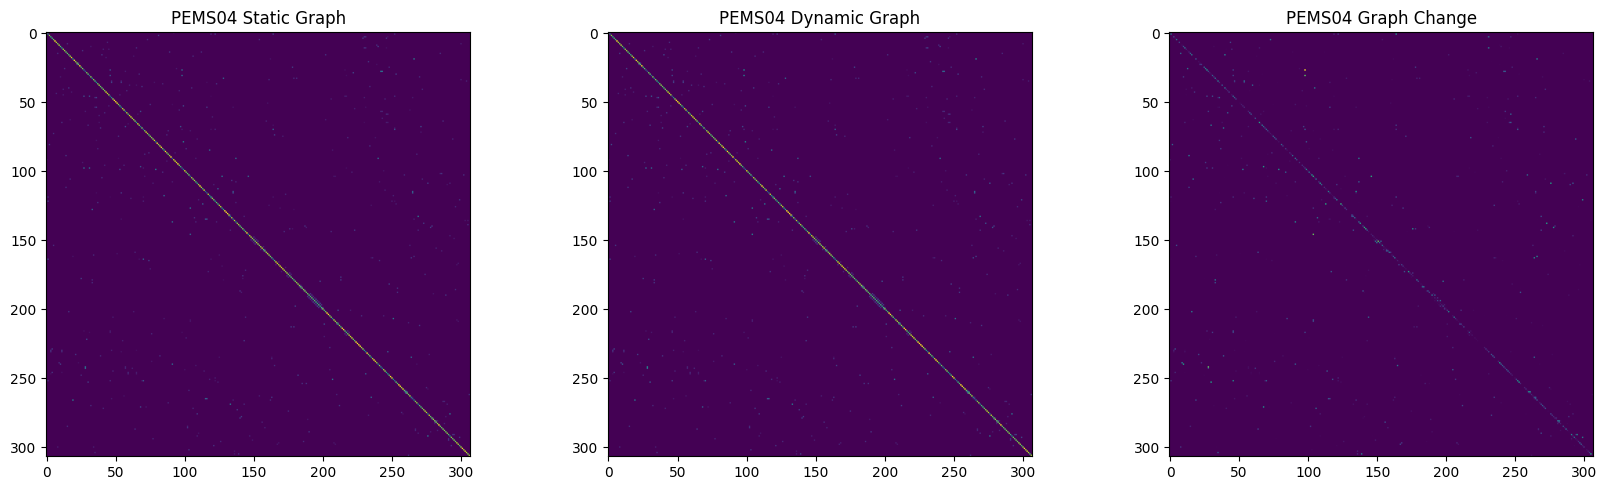

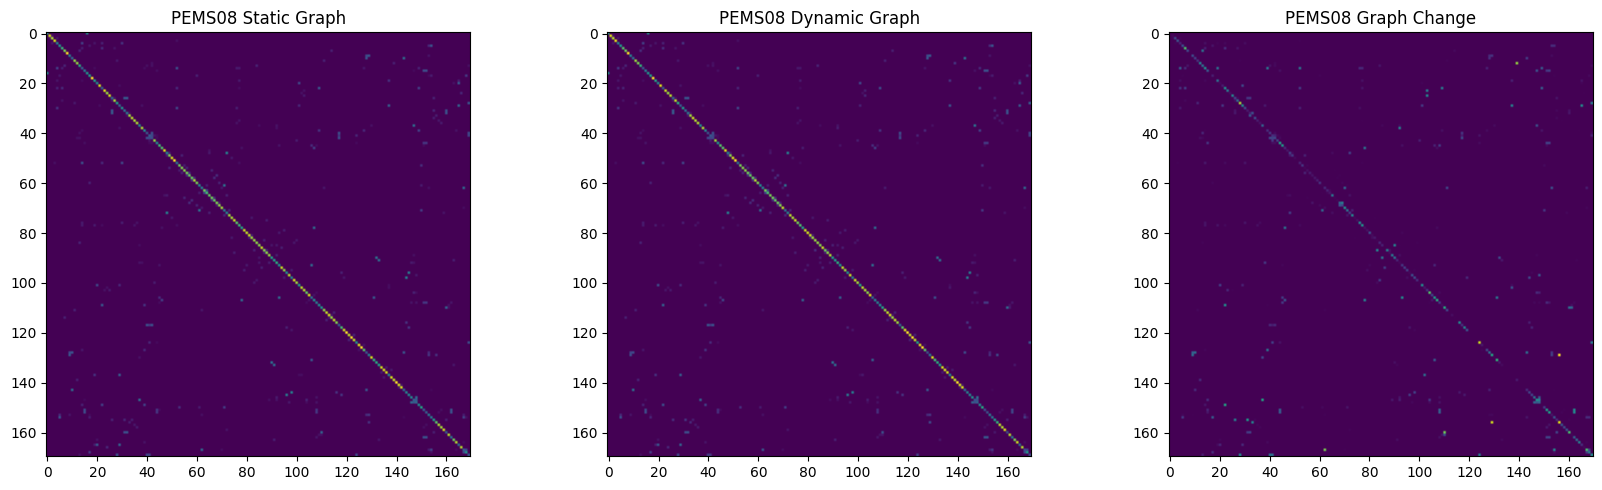

In [ ]:
# ============================================================
# 28. DYNAMIC GRAPH VISUALIZATION
# ============================================================
for dataset_name in DATASETS:

    key = (
        dataset_name,
        "Adaptive-CASTNet",
        FINAL_SEEDS[0]
    )

    model = ALL_MODELS[key]

    model.eval()

    A_static = torch.tensor(
        GRAPH_INFO[
            dataset_name
        ]["A_norm"],
        dtype=torch.float32,
        device=DEVICE
    )

    x_demo, _ = next(
        iter(
            LOADERS[
                dataset_name
            ][2]
        )
    )

    x_demo = x_demo.to(
        DEVICE
    )

    with torch.no_grad():

        _, dynamic = model(
            x_demo,
            A_static,
            return_graph=True
        )

    dynamic_mean = (
        dynamic.mean(0)
        .cpu()
        .numpy()
    )

    static_np = (
        A_static.cpu().numpy()
    )

    diff = np.abs(
        dynamic_mean
        - static_np
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(17,5)
    )

    axes[0].imshow(
        static_np
    )

    axes[0].set_title(
        f"{dataset_name} Static Graph"
    )

    axes[1].imshow(
        dynamic_mean
    )

    axes[1].set_title(
        f"{dataset_name} Dynamic Graph"
    )

    axes[2].imshow(
        diff
    )

    axes[2].set_title(
        f"{dataset_name} Graph Change"
    )

    plt.tight_layout()
    plt.show()


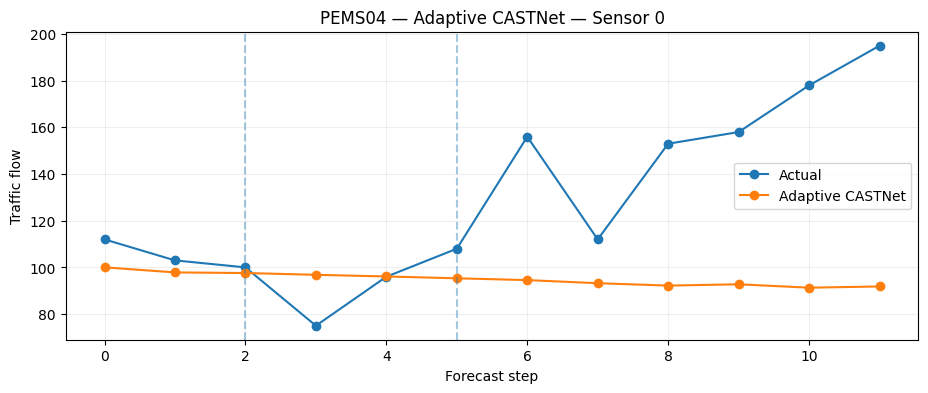

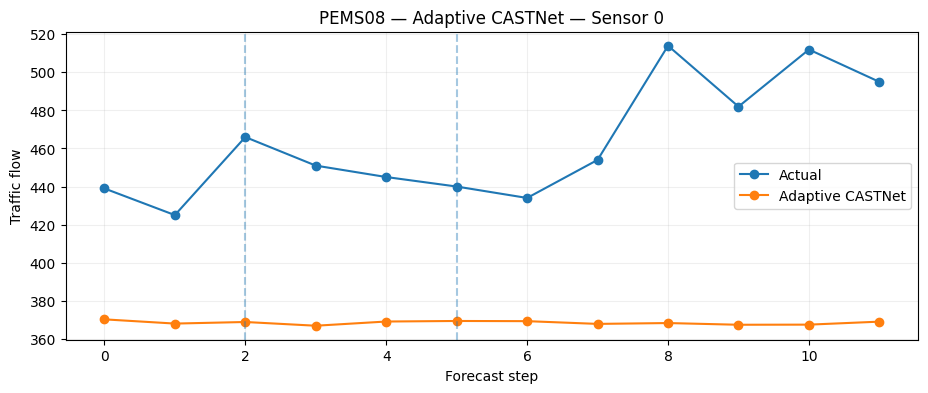

In [ ]:
# ============================================================
# 29. ACTUAL VS PREDICTED
# ============================================================
for dataset_name in DATASETS:

    key = (
        dataset_name,
        "Adaptive-CASTNet",
        FINAL_SEEDS[0]
    )

    model = ALL_MODELS[key]

    A = torch.tensor(
        GRAPH_INFO[
            dataset_name
        ]["A_norm"],
        dtype=torch.float32,
        device=DEVICE
    )

    y_test, p_test = predict_loader(
        model,
        "Adaptive-CASTNet",
        LOADERS[
            dataset_name
        ][2],
        A
    )

    actual = inverse_scale(
        y_test,
        DATA_INFO[dataset_name]["mean"],
        DATA_INFO[dataset_name]["std"]
    )

    predicted = inverse_scale(
        p_test,
        DATA_INFO[dataset_name]["mean"],
        DATA_INFO[dataset_name]["std"]
    )

    sensor_id = 0
    sample_id = 0

    plt.figure(figsize=(11,4))

    plt.plot(
        actual[
            sample_id,:,sensor_id,0
        ],
        marker="o",
        label="Actual"
    )

    plt.plot(
        predicted[
            sample_id,:,sensor_id,0
        ],
        marker="o",
        label="Adaptive CASTNet"
    )

    plt.axvline(
        2,
        linestyle="--",
        alpha=0.4
    )

    plt.axvline(
        5,
        linestyle="--",
        alpha=0.4
    )

    plt.xlabel(
        "Forecast step"
    )

    plt.ylabel(
        "Traffic flow"
    )

    plt.title(
        f"{dataset_name} — Adaptive CASTNet — Sensor {sensor_id}"
    )

    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


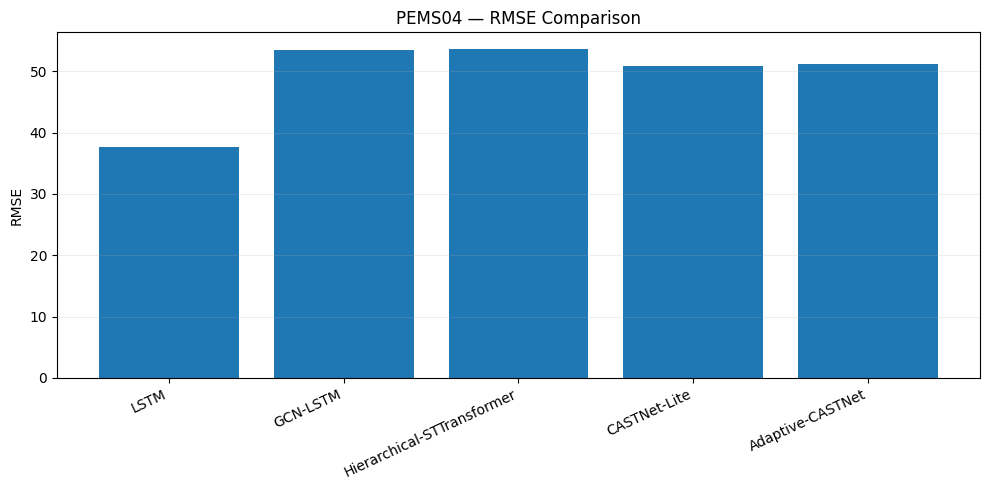

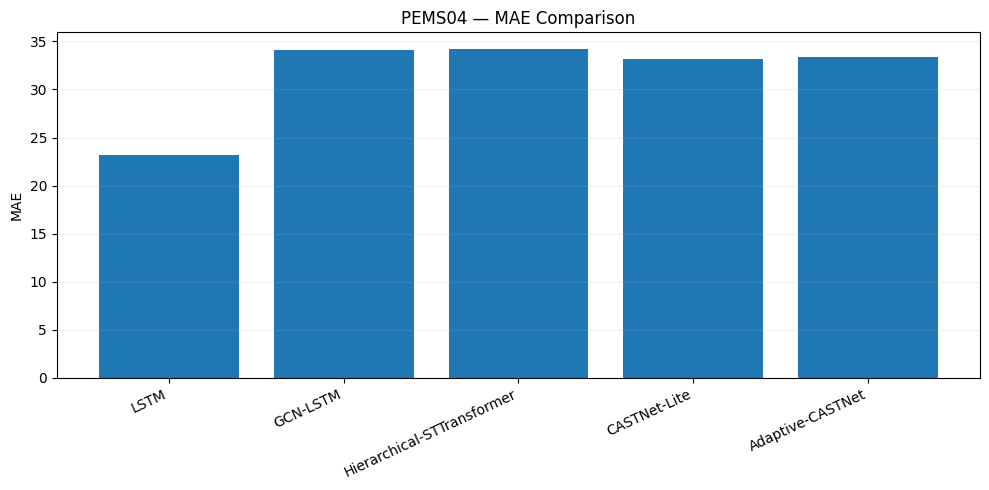

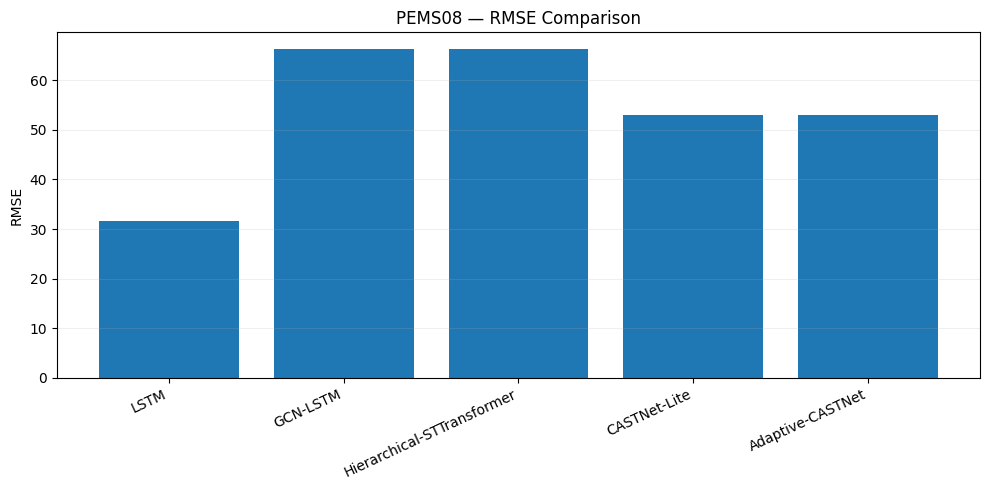

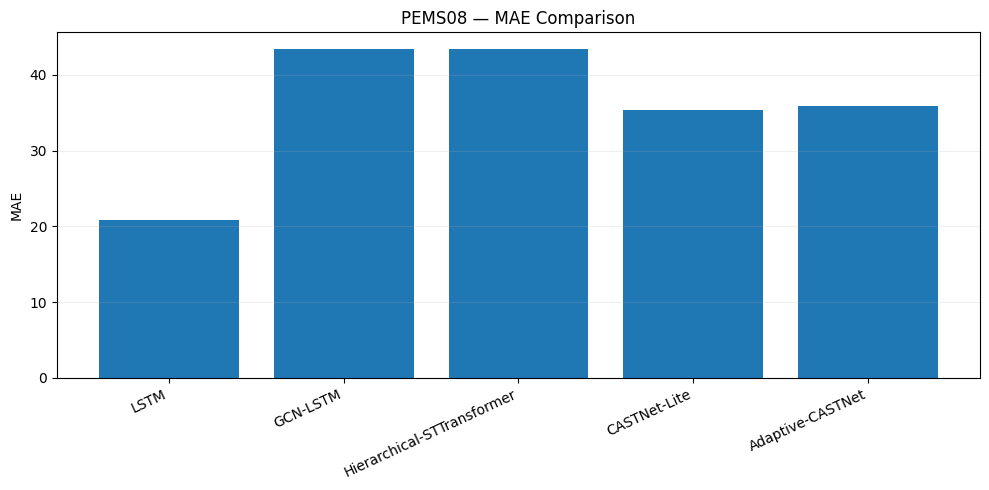

In [ ]:
# ============================================================
# 30. MODEL COMPARISON
# ============================================================
for dataset_name in DATASETS:

    sub = results_df[
        results_df["Dataset"]
        == dataset_name
    ].copy()

    plt.figure(figsize=(10,5))

    plt.bar(
        sub["Model"],
        sub["RMSE"]
    )

    plt.ylabel(
        "RMSE"
    )

    plt.title(
        f"{dataset_name} — RMSE Comparison"
    )

    plt.xticks(
        rotation=25,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10,5))

    plt.bar(
        sub["Model"],
        sub["MAE"]
    )

    plt.ylabel(
        "MAE"
    )

    plt.title(
        f"{dataset_name} — MAE Comparison"
    )

    plt.xticks(
        rotation=25,
        ha="right"
    )

    plt.grid(
        axis="y",
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()


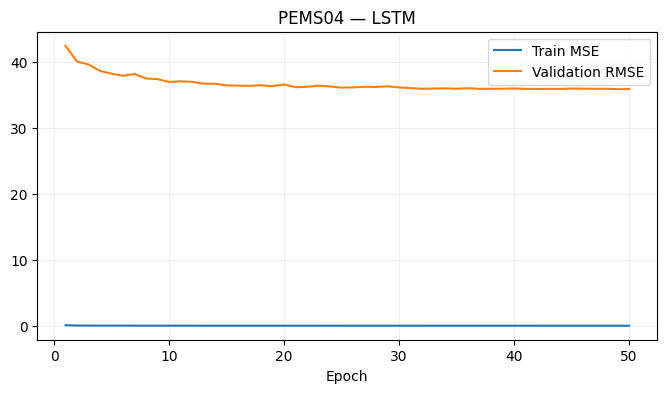

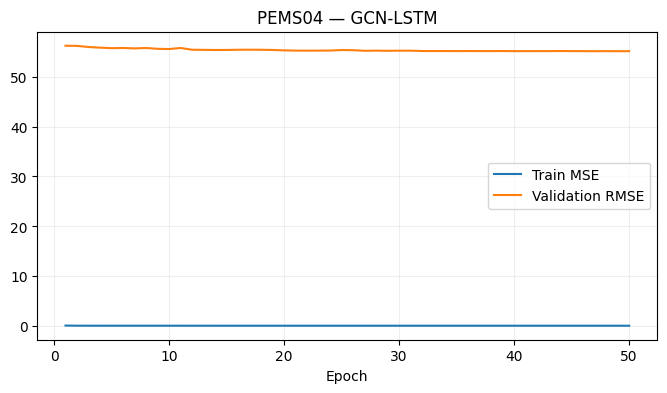

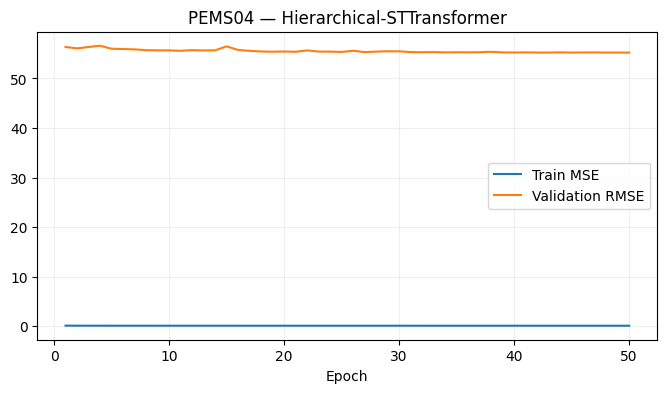

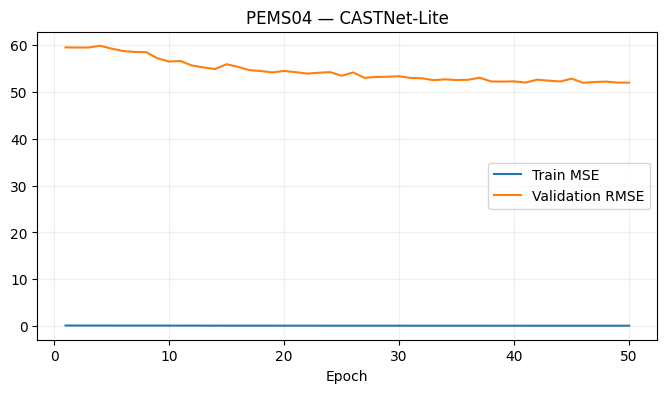

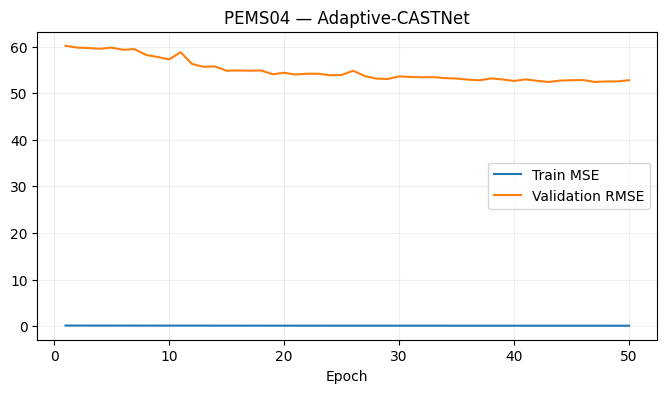

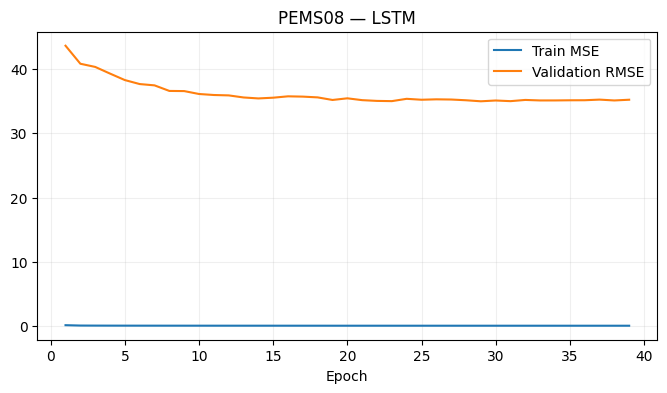

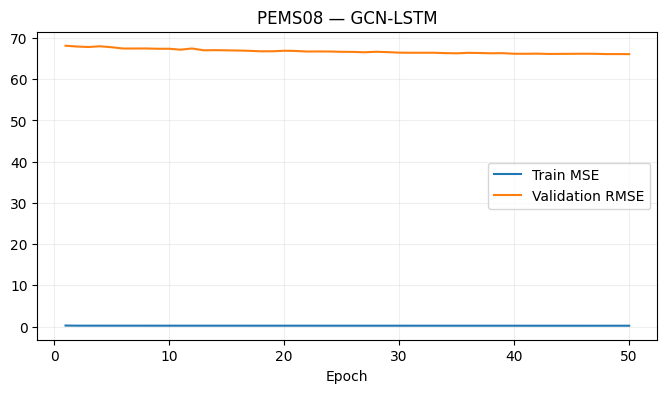

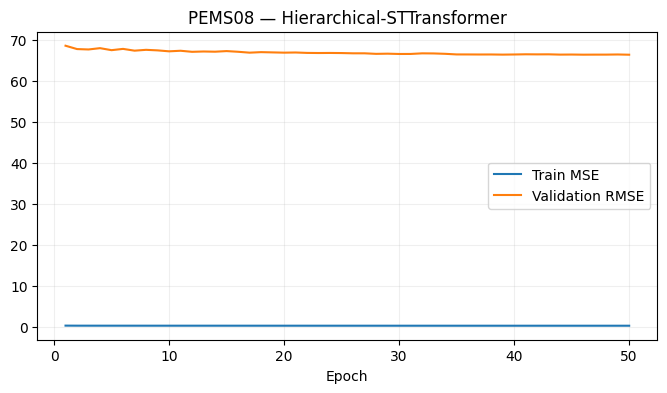

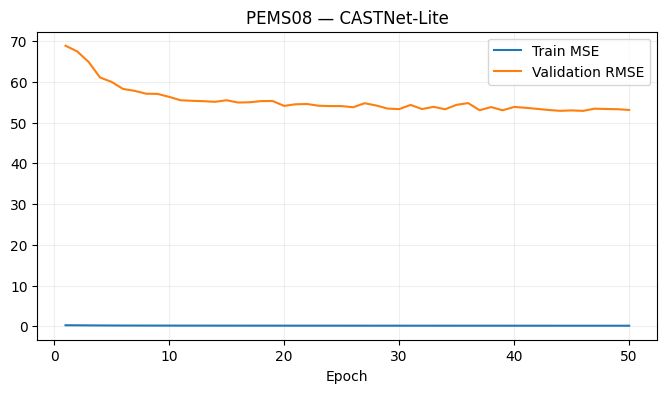

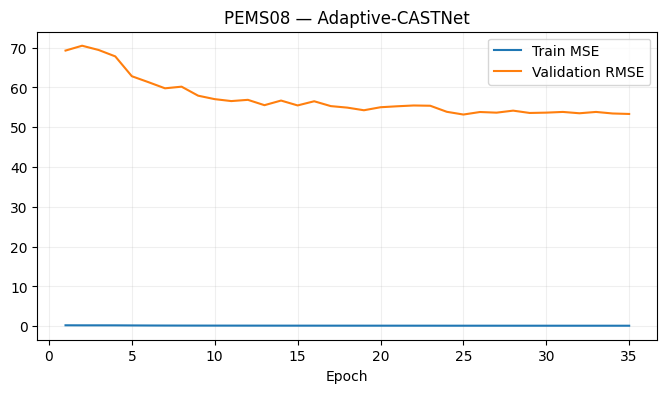

In [ ]:
# ============================================================
# 31. TRAINING CURVES
# ============================================================
for (
    dataset_name,
    model_name,
    seed
), history in ALL_HISTORIES.items():

    plt.figure(figsize=(8,4))

    plt.plot(
        history["epoch"],
        history["train_MSE"],
        label="Train MSE"
    )

    plt.plot(
        history["epoch"],
        history["val_RMSE"],
        label="Validation RMSE"
    )

    plt.title(
        f"{dataset_name} — {model_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()


# 13. Multi-seed robustness

For a final paper-quality result, repeat the experiment with:

```python
FINAL_SEEDS = [42, 123, 2026]
```

This is intentionally separated from the first full run because it multiplies training time by three.

The report should then use:

> **mean ± standard deviation**

instead of a single random-seed number.


In [ ]:
# ============================================================
# 32. MULTI-SEED SUMMARY TEMPLATE
# ============================================================
# After rerunning the FULL EXPERIMENT with:
#
# FINAL_SEEDS = [42, 123, 2026]
#
# execute:
#
# summary_df = (
#     results_df
#     .groupby(["Dataset","Model"])
#     [["MAE","RMSE","MAPE","R2"]]
#     .agg(["mean","std"])
#     .reset_index()
# )
#
# display(summary_df)

print(
    "Current run seeds:",
    FINAL_SEEDS
)

if len(FINAL_SEEDS) == 1:
    print(
        "For the strongest final report, repeat with "
        "seeds [42, 123, 2026]."
    )


Current run seeds: [42]
For the strongest final report, repeat with seeds [42, 123, 2026].


In [ ]:
# ============================================================
# 33. SAVE ALL RESULTS
# ============================================================
RESULT_DIR = "/content/adaptive_castnet_results"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "final_model_results.csv"
    ),
    index=False
)

horizon_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "multi_horizon_results.csv"
    ),
    index=False
)

difficult_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "difficult_condition_results.csv"
    ),
    index=False
)

compute_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "computational_results.csv"
    ),
    index=False
)

# Save histories.
history_records = []

for key, hist in ALL_HISTORIES.items():

    dataset_name, model_name, seed = key

    h = hist.copy()

    h["Dataset"] = dataset_name
    h["Model"] = model_name
    h["Seed"] = seed

    history_records.append(h)

history_df = pd.concat(
    history_records,
    ignore_index=True
)

history_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "training_histories.csv"
    ),
    index=False
)

print(
    "All results saved to:",
    RESULT_DIR
)


All results saved to: /content/adaptive_castnet_results


In [ ]:
# ============================================================
# 34. SAVE CHECKPOINTS
# ============================================================
CHECKPOINT_DIR = os.path.join(
    RESULT_DIR,
    "checkpoints"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

for (
    dataset_name,
    model_name,
    seed
), model in ALL_MODELS.items():

    filename = (
        f"{dataset_name}_"
        f"{model_name}_"
        f"seed{seed}.pt"
    )

    path = os.path.join(
        CHECKPOINT_DIR,
        filename
    )

    torch.save(
        {
            "dataset": dataset_name,
            "model": model_name,
            "seed": seed,
            "state_dict": model.state_dict(),
            "mean": DATA_INFO[
                dataset_name
            ]["mean"],
            "std": DATA_INFO[
                dataset_name
            ]["std"],
            "input_steps": INPUT_STEPS,
            "forecast_horizon": FORECAST_HORIZON,
            "hidden": HIDDEN,
            "heads": HEADS,
            "topk": TOPK
        },
        path
    )

print(
    "Checkpoints saved."
)


Checkpoints saved.


# 14. Final report checklist

## Dataset
- [ ] PEMS04
- [ ] PEMS08
- [ ] Full sensor sets
- [ ] 60/20/20 chronological split
- [ ] Training-only normalization

## Models
- [ ] LSTM
- [ ] GCN-LSTM
- [ ] Hierarchical ST-Transformer
- [ ] CASTNet-Lite
- [ ] Adaptive CASTNet

## Metrics
- [ ] MAE
- [ ] RMSE
- [ ] MAPE
- [ ] R²
- [ ] 15-minute
- [ ] 30-minute
- [ ] 60-minute

## Research analysis
- [ ] Adaptive vs static graph ablation
- [ ] Difficult/low-flow analysis
- [ ] Dynamic graph visualization
- [ ] Parameter count
- [ ] Inference time
- [ ] Training curves
- [ ] Actual vs predicted plots
- [ ] Multiple random seeds

## Main claim

Do **not** decide the winner before running the experiment.

The final conclusion should be based on the measured results across both datasets and, ideally, multiple seeds.


METER-LA


In [ ]:
# ============================================================
# METR-LA ORIGINAL DATASET — LOAD
# ============================================================

import os
import csv
import urllib.request
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

METR_DIR = "/content/metr_la_original"
os.makedirs(METR_DIR, exist_ok=True)

METR_H5 = os.path.join(
    METR_DIR,
    "metr-la.h5"
)

METR_URL = (
    "https://huggingface.co/datasets/MintBruce/SkyTraffic/"
    "resolve/main/metr-la.h5?download=true"
)

if not os.path.exists(METR_H5):

    print("Downloading METR-LA...")

    urllib.request.urlretrieve(
        METR_URL,
        METR_H5
    )

print(
    "METR-LA file:",
    METR_H5
)

print(
    "Size:",
    f"{os.path.getsize(METR_H5)/1e6:.2f} MB"
)

# Load HDF5
with pd.HDFStore(
    METR_H5,
    mode="r"
) as store:

    print(
        "HDF keys:",
        store.keys()
    )

    metr_df = store["/df"]

METR_RAW = metr_df.values.astype(
    np.float32
)

METR_RAW = np.nan_to_num(
    METR_RAW,
    nan=np.nanmedian(METR_RAW),
    posinf=0.0,
    neginf=0.0
)

print(
    "\nMETR-LA shape:",
    METR_RAW.shape
)

print(
    "Time steps:",
    METR_RAW.shape[0]
)

print(
    "Sensors:",
    METR_RAW.shape[1]
)

print(
    "\nMETR-LA uses traffic SPEED as the target."
)

display(
    metr_df.head()
)

METR-LA file: /content/metr_la_original/metr-la.h5
Size: 57.04 MB
HDF keys: ['/df']

METR-LA shape: (34272, 207)
Time steps: 34272
Sensors: 207

METR-LA uses traffic SPEED as the target.


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000


Build the original METR-LA graph

In [ ]:
# ============================================================
# METR-LA GRAPH
# ============================================================

METR_GRAPH_BASE = (
    "https://raw.githubusercontent.com/"
    "liyaguang/DCRNN/master/data/sensor_graph/"
)

METR_SENSOR_IDS_URL = (
    METR_GRAPH_BASE +
    "graph_sensor_ids.txt"
)

METR_DISTANCE_URL = (
    METR_GRAPH_BASE +
    "distances_la_2012.csv"
)

METR_SENSOR_FILE = os.path.join(
    METR_DIR,
    "graph_sensor_ids.txt"
)

METR_DISTANCE_FILE = os.path.join(
    METR_DIR,
    "distances_la_2012.csv"
)

if not os.path.exists(
    METR_SENSOR_FILE
):

    urllib.request.urlretrieve(
        METR_SENSOR_IDS_URL,
        METR_SENSOR_FILE
    )

if not os.path.exists(
    METR_DISTANCE_FILE
):

    urllib.request.urlretrieve(
        METR_DISTANCE_URL,
        METR_DISTANCE_FILE
    )


# ------------------------------------------------------------
# Sensor IDs
# ------------------------------------------------------------

with open(
    METR_SENSOR_FILE,
    "r"
) as f:

    metr_sensor_ids = (
        f.read()
        .strip()
        .split(",")
    )

print(
    "Number of graph sensors:",
    len(metr_sensor_ids)
)


# ------------------------------------------------------------
# Build distance matrix
# ------------------------------------------------------------

METR_N = len(metr_sensor_ids)

sensor_to_idx = {
    sensor_id: i
    for i, sensor_id
    in enumerate(metr_sensor_ids)
}

metr_dist = np.full(
    (
        METR_N,
        METR_N
    ),
    np.inf,
    dtype=np.float32
)


with open(
    METR_DISTANCE_FILE,
    "r"
) as f:

    reader = csv.DictReader(f)

    for row in reader:

        source = row["from"]
        target = row["to"]

        if (
            source in sensor_to_idx
            and target in sensor_to_idx
        ):

            i = sensor_to_idx[source]
            j = sensor_to_idx[target]

            metr_dist[i, j] = float(
                row["cost"]
            )


# ------------------------------------------------------------
# Gaussian distance kernel
# ------------------------------------------------------------

finite_dist = metr_dist[
    np.isfinite(metr_dist)
]

sigma = (
    finite_dist.std()
    + 1e-6
)

METR_ADJ = np.exp(
    -np.square(
        metr_dist / sigma
    )
)

METR_ADJ[
    ~np.isfinite(METR_ADJ)
] = 0.0


# Remove extremely weak edges
METR_ADJ[
    METR_ADJ < 0.1
] = 0.0


# Symmetric graph
METR_ADJ = np.maximum(
    METR_ADJ,
    METR_ADJ.T
)


# Self loops
np.fill_diagonal(
    METR_ADJ,
    1.0
)


# Symmetric normalization
degree = METR_ADJ.sum(
    axis=1
)

degree_inv_sqrt = (
    1.0 /
    np.sqrt(
        np.maximum(
            degree,
            1e-8
        )
    )
)

METR_A_NORM = (
    degree_inv_sqrt[:, None]
    * METR_ADJ
    * degree_inv_sqrt[None, :]
).astype(
    np.float32
)


print(
    "\nMETR adjacency:",
    METR_ADJ.shape
)

print(
    "Number of edges:",
    np.count_nonzero(METR_ADJ)
)

Number of graph sensors: 207

METR adjacency: (207, 207)
Number of edges: 2833


Prepare METR-LA train/validation/test

In [ ]:
# ============================================================
# METR-LA DATA PREPARATION
# ============================================================

METR_INPUT_STEPS = 12
METR_HORIZON = 12

METR_BATCH_SIZE = 16

METR_T = METR_RAW.shape[0]

# Use all 207 sensors
METR_TRAFFIC = METR_RAW[
    :,
    :METR_N
]

# ------------------------------------------------------------
# Chronological 60 / 20 / 20 split
# ------------------------------------------------------------

METR_TRAIN_END = int(
    METR_T * 0.60
)

METR_VAL_END = int(
    METR_T * 0.80
)


# ------------------------------------------------------------
# Normalize using training data ONLY
# ------------------------------------------------------------

METR_TRAIN_RAW = METR_TRAFFIC[
    :METR_TRAIN_END
]

METR_MEAN = float(
    METR_TRAIN_RAW.mean()
)

METR_STD = float(
    METR_TRAIN_RAW.std()
    + 1e-6
)

METR_NORM = (
    METR_TRAFFIC
    - METR_MEAN
) / METR_STD


print(
    "METR-LA preprocessing"
)

print(
    "Total time steps:",
    METR_T
)

print(
    "Sensors:",
    METR_N
)

print(
    "Train:",
    METR_TRAIN_END
)

print(
    "Validation:",
    METR_VAL_END - METR_TRAIN_END
)

print(
    "Test:",
    METR_T - METR_VAL_END
)

print(
    "\nTraining mean:",
    METR_MEAN
)

print(
    "Training std:",
    METR_STD
)

METR-LA preprocessing
Total time steps: 34272
Sensors: 207
Train: 20563
Validation: 6854
Test: 6855

Training mean: 54.09928512573242
Training std: 19.843467712402344


Create METR-LA loaders

In [ ]:
# ============================================================
# METR-LA WINDOW DATASETS
# ============================================================

METR_TRAIN_DS = TrafficWindowDataset(
    METR_NORM,
    0,
    METR_TRAIN_END,
    METR_INPUT_STEPS,
    METR_HORIZON
)

METR_VAL_DS = TrafficWindowDataset(
    METR_NORM,
    METR_TRAIN_END,
    METR_VAL_END,
    METR_INPUT_STEPS,
    METR_HORIZON
)

METR_TEST_DS = TrafficWindowDataset(
    METR_NORM,
    METR_VAL_END,
    METR_T,
    METR_INPUT_STEPS,
    METR_HORIZON
)


METR_TRAIN_LOADER = DataLoader(
    METR_TRAIN_DS,
    batch_size=METR_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

METR_VAL_LOADER = DataLoader(
    METR_VAL_DS,
    batch_size=METR_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

METR_TEST_LOADER = DataLoader(
    METR_TEST_DS,
    batch_size=METR_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)


print(
    "METR-LA windows:"
)

print(
    "Train:",
    len(METR_TRAIN_DS)
)

print(
    "Validation:",
    len(METR_VAL_DS)
)

print(
    "Test:",
    len(METR_TEST_DS)
)

METR-LA windows:
Train: 20540
Validation: 6831
Test: 6832


Train/evaluate METR-LA

In [ ]:
# ============================================================
# METR-LA — TRAIN ALL FIVE MODELS
# ============================================================

METR_EPOCHS = 50
METR_PATIENCE = 10
METR_SEED = 42

METR_MODEL_NAMES = [
    "LSTM",
    "GCN-LSTM",
    "Hierarchical-STTransformer",
    "CASTNet-Lite",
    "Adaptive-CASTNet"
]


def metr_forward(
    model,
    model_name,
    x,
    A
):

    if model_name == "LSTM":

        return model(x)

    return model(
        x,
        A
    )


def metr_train_one_epoch(
    model,
    model_name,
    loader,
    optimizer,
    scaler,
    A
):

    model.train()

    losses = []

    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        use_amp = (
            DEVICE.type == "cuda"
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):

            pred = metr_forward(
                model,
                model_name,
                x,
                A
            )

            loss = F.mse_loss(
                pred,
                y
            )

        if use_amp:

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

        losses.append(
            loss.item()
        )

    return float(
        np.mean(losses)
    )


@torch.no_grad()
def metr_predict(
    model,
    model_name,
    loader,
    A
):

    model.eval()

    y_true = []
    y_pred = []

    for x, y in loader:

        x = x.to(
            DEVICE,
            non_blocking=True
        )

        pred = metr_forward(
            model,
            model_name,
            x,
            A
        )

        y_true.append(
            y.numpy()
        )

        y_pred.append(
            pred.float()
            .cpu()
            .numpy()
        )

    return (
        np.concatenate(
            y_true,
            axis=0
        ),
        np.concatenate(
            y_pred,
            axis=0
        )
    )


def metr_metrics(
    y_true,
    y_pred
):

    yt = (
        y_true
        * METR_STD
        + METR_MEAN
    )

    yp = (
        y_pred
        * METR_STD
        + METR_MEAN
    )

    yt_flat = yt.reshape(-1)
    yp_flat = yp.reshape(-1)

    mae = mean_absolute_error(
        yt_flat,
        yp_flat
    )

    rmse = np.sqrt(
        mean_squared_error(
            yt_flat,
            yp_flat
        )
    )

    # Robust MAPE
    mask = (
        np.abs(yt_flat)
        > 1e-5
    )

    mape = (
        np.mean(
            np.abs(
                (
                    yt_flat[mask]
                    - yp_flat[mask]
                )
                / yt_flat[mask]
            )
        )
        * 100
    )

    r2 = r2_score(
        yt_flat,
        yp_flat
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "MAPE": float(mape),
        "R2": float(r2)
    }


# ------------------------------------------------------------
# METR-LA experiment
# ------------------------------------------------------------

METR_RESULTS = []
METR_HISTORIES = {}
METR_MODELS = {}

METR_A_TENSOR = torch.tensor(
    METR_A_NORM,
    dtype=torch.float32,
    device=DEVICE
)


for model_name in METR_MODEL_NAMES:

    print(
        "\n" + "=" * 75
    )

    print(
        f"METR-LA | {model_name}"
    )

    print(
        "=" * 75
    )

    set_seed(
        METR_SEED
    )

    model = make_model(
        model_name,
        METR_N
    ).to(
        DEVICE
    )

    print(
        "Parameters:",
        f"{count_parameters(model):,}"
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(
            DEVICE.type == "cuda"
        )
    )

    best_val_rmse = float(
        "inf"
    )

    best_state = None

    patience_counter = 0

    history = []


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    for epoch in range(
        1,
        METR_EPOCHS + 1
    ):

        start_time = time.time()

        train_loss = metr_train_one_epoch(
            model,
            model_name,
            METR_TRAIN_LOADER,
            optimizer,
            scaler,
            METR_A_TENSOR
        )

        y_val, p_val = metr_predict(
            model,
            model_name,
            METR_VAL_LOADER,
            METR_A_TENSOR
        )

        val_metrics = metr_metrics(
            y_val,
            p_val
        )

        scheduler.step(
            val_metrics["RMSE"]
        )

        history.append({
            "epoch": epoch,
            "train_MSE": train_loss,
            "val_MAE": val_metrics["MAE"],
            "val_RMSE": val_metrics["RMSE"],
            "val_MAPE": val_metrics["MAPE"],
            "val_R2": val_metrics["R2"],
            "lr": optimizer.param_groups[0]["lr"]
        })

        elapsed = (
            time.time()
            - start_time
        )

        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE {train_loss:.5f} | "
            f"Val RMSE {val_metrics['RMSE']:.4f} | "
            f"Val MAE {val_metrics['MAE']:.4f} | "
            f"{elapsed:.1f}s"
        )


        # ----------------------------------------------------
        # Best validation checkpoint
        # ----------------------------------------------------

        if (
            val_metrics["RMSE"]
            < best_val_rmse
        ):

            best_val_rmse = (
                val_metrics["RMSE"]
            )

            best_state = {
                k: v.detach()
                .cpu()
                .clone()
                for k, v
                in model.state_dict().items()
            }

            patience_counter = 0

        else:

            patience_counter += 1


        if (
            patience_counter
            >= METR_PATIENCE
        ):

            print(
                "Early stopping."
            )

            break


    # --------------------------------------------------------
    # Restore best validation checkpoint
    # --------------------------------------------------------

    model.load_state_dict(
        best_state
    )


    # --------------------------------------------------------
    # Final TEST evaluation
    # --------------------------------------------------------

    y_test, p_test = metr_predict(
        model,
        model_name,
        METR_TEST_LOADER,
        METR_A_TENSOR
    )

    test_metrics = metr_metrics(
        y_test,
        p_test
    )


    row = {
        "Dataset": "METR-LA",
        "Target": "Speed",
        "Model": model_name,
        "Seed": METR_SEED,
        "Parameters": count_parameters(model),
        **test_metrics
    }

    METR_RESULTS.append(
        row
    )

    METR_HISTORIES[
        model_name
    ] = pd.DataFrame(
        history
    )

    METR_MODELS[
        model_name
    ] = model

    print(
        "\nTEST RESULTS:"
    )

    print(
        test_metrics
    )

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


METR_RESULTS_DF = pd.DataFrame(
    METR_RESULTS
)

display(
    METR_RESULTS_DF
)


METR-LA | LSTM
Parameters: 231,348
Epoch 001 | Train MSE 0.35574 | Val RMSE 12.4680 | Val MAE 7.1483 | 9.4s
Epoch 002 | Train MSE 0.26615 | Val RMSE 12.1869 | Val MAE 7.2632 | 9.7s
Epoch 003 | Train MSE 0.23856 | Val RMSE 12.3132 | Val MAE 7.2685 | 9.6s
Epoch 004 | Train MSE 0.22774 | Val RMSE 12.2310 | Val MAE 7.0270 | 8.6s
Epoch 005 | Train MSE 0.21816 | Val RMSE 13.5962 | Val MAE 8.5221 | 10.1s
Epoch 006 | Train MSE 0.21459 | Val RMSE 12.3259 | Val MAE 7.2544 | 9.9s
Epoch 007 | Train MSE 0.20363 | Val RMSE 12.2034 | Val MAE 6.9325 | 9.3s
Epoch 008 | Train MSE 0.20106 | Val RMSE 12.1912 | Val MAE 6.9178 | 9.0s
Epoch 009 | Train MSE 0.19879 | Val RMSE 12.1170 | Val MAE 6.9040 | 10.2s
Epoch 010 | Train MSE 0.19626 | Val RMSE 11.9888 | Val MAE 6.8159 | 10.1s
Epoch 011 | Train MSE 0.19613 | Val RMSE 12.3376 | Val MAE 7.1067 | 9.5s
Epoch 012 | Train MSE 0.19401 | Val RMSE 12.4598 | Val MAE 7.1353 | 9.3s
Epoch 013 | Train MSE 0.19302 | Val RMSE 12.2859 | Val MAE 7.0977 | 9.9s
Epoch 014 | 

,Dataset,Target,Model,Seed,Parameters,MAE,RMSE,MAPE,R2
0,METR-LA,Speed,LSTM,42,231348,8.215672,14.312107,15.238486,0.605721
1,METR-LA,Speed,GCN-LSTM,42,34188,8.228846,13.784609,17.270241,0.634249
2,METR-LA,Speed,Hierarchical-STTransformer,42,113356,8.211530,13.757664,17.156717,0.635678
3,METR-LA,Speed,CASTNet-Lite,42,63180,7.856597,13.452269,16.469629,0.651673
4,METR-LA,Speed,Adaptive-CASTNet,42,71372,7.966737,13.473968,16.714241,0.650548


15 / 30 / 60 minute METR-LA results

In [ ]:
# ============================================================
# METR-LA — MULTI-HORIZON RESULTS
# ============================================================

METR_HORIZON_RESULTS = []

for model_name in METR_MODEL_NAMES:

    model = METR_MODELS[
        model_name
    ]

    y_test, p_test = metr_predict(
        model,
        model_name,
        METR_TEST_LOADER,
        METR_A_TENSOR
    )

    for h, minutes in [
        (3, 15),
        (6, 30),
        (12, 60)
    ]:

        yt = (
            y_test[:, :h]
            * METR_STD
            + METR_MEAN
        )

        yp = (
            p_test[:, :h]
            * METR_STD
            + METR_MEAN
        )

        yt_flat = yt.reshape(-1)
        yp_flat = yp.reshape(-1)

        mae = mean_absolute_error(
            yt_flat,
            yp_flat
        )

        rmse = np.sqrt(
            mean_squared_error(
                yt_flat,
                yp_flat
            )
        )

        mask = (
            np.abs(yt_flat)
            > 1e-5
        )

        mape = (
            np.mean(
                np.abs(
                    (
                        yt_flat[mask]
                        - yp_flat[mask]
                    )
                    / yt_flat[mask]
                )
            )
            * 100
        )

        r2 = r2_score(
            yt_flat,
            yp_flat
        )

        METR_HORIZON_RESULTS.append({
            "Dataset": "METR-LA",
            "Model": model_name,
            "Horizon": f"{minutes} min",
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape,
            "R2": r2
        })


METR_HORIZON_DF = pd.DataFrame(
    METR_HORIZON_RESULTS
)

display(
    METR_HORIZON_DF
)

,Dataset,Model,Horizon,MAE,RMSE,MAPE,R2
0,METR-LA,LSTM,15 min,6.530523,11.359041,12.829704,0.751622
1,METR-LA,LSTM,30 min,7.108070,12.477217,13.594772,0.700325
2,METR-LA,LSTM,60 min,8.215672,14.312107,15.238486,0.605721
3,METR-LA,GCN-LSTM,15 min,6.502487,11.172724,14.148615,0.759703
4,METR-LA,GCN-LSTM,30 min,7.128263,12.214109,15.257020,0.712831
5,METR-LA,GCN-LSTM,60 min,8.228846,13.784609,17.270241,0.634249
6,METR-LA,Hierarchical-STTransformer,15 min,6.624658,11.116586,14.106991,0.762112
7,METR-LA,Hierarchical-STTransformer,30 min,7.208565,12.167187,15.191343,0.715033
8,METR-LA,Hierarchical-STTransformer,60 min,8.211530,13.757664,17.156717,0.635678
9,METR-LA,CASTNet-Lite,15 min,6.014081,10.491529,13.017405,0.788111


save the METR-LA results

In [ ]:
# ============================================================
# SAVE METR-LA RESULTS
# ============================================================

METR_RESULT_DIR = os.path.join(
    RESULT_DIR,
    "METR-LA"
)

os.makedirs(
    METR_RESULT_DIR,
    exist_ok=True
)

METR_RESULTS_DF.to_csv(
    os.path.join(
        METR_RESULT_DIR,
        "metr_la_model_results.csv"
    ),
    index=False
)

METR_HORIZON_DF.to_csv(
    os.path.join(
        METR_RESULT_DIR,
        "metr_la_horizon_results.csv"
    ),
    index=False
)

print(
    "Saved METR-LA results to:"
)

print(
    METR_RESULT_DIR
)

Saved METR-LA results to:
/content/adaptive_castnet_results/METR-LA


final combined table

In [ ]:
# ============================================================
# FINAL DATASET-WISE SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("METR-LA FINAL RESULTS")
print("=" * 80)

display(
    METR_RESULTS_DF[
        [
            "Dataset",
            "Target",
            "Model",
            "Parameters",
            "MAE",
            "RMSE",
            "MAPE",
            "R2"
        ]
    ].sort_values(
        "RMSE"
    )
)


print("\n" + "=" * 80)
print("PEMS04 + PEMS08 FINAL RESULTS")
print("=" * 80)

display(
    results_df[
        [
            "Dataset",
            "Model",
            "Parameters",
            "MAE",
            "RMSE",
            "MAPE",
            "R2"
        ]
    ]
)


METR-LA FINAL RESULTS


,Dataset,Target,Model,Parameters,MAE,RMSE,MAPE,R2
3,METR-LA,Speed,CASTNet-Lite,63180,7.856597,13.452269,16.469629,0.651673
4,METR-LA,Speed,Adaptive-CASTNet,71372,7.966737,13.473968,16.714241,0.650548
2,METR-LA,Speed,Hierarchical-STTransformer,113356,8.211530,13.757664,17.156717,0.635678
1,METR-LA,Speed,GCN-LSTM,34188,8.228846,13.784609,17.270241,0.634249
0,METR-LA,Speed,LSTM,231348,8.215672,14.312107,15.238486,0.605721



PEMS04 + PEMS08 FINAL RESULTS


,Dataset,Model,Parameters,MAE,RMSE,MAPE,R2
0,PEMS04,LSTM,334948,23.158745,37.570965,16.436117,0.943615
1,PEMS04,GCN-LSTM,34188,34.117085,53.531606,26.488581,0.885533
2,PEMS04,Hierarchical-STTransformer,113356,34.224247,53.652567,26.995728,0.885015
3,PEMS04,CASTNet-Lite,63180,33.135391,50.903648,25.535429,0.896496
4,PEMS04,Adaptive-CASTNet,71372,33.369438,51.235938,26.204792,0.895140
5,PEMS08,LSTM,193016,20.813143,31.665020,13.667297,0.953088
6,PEMS08,GCN-LSTM,34188,43.407265,66.204370,60.379452,0.794934
7,PEMS08,Hierarchical-STTransformer,113356,43.442574,66.320264,59.618805,0.794215
8,PEMS08,CASTNet-Lite,63180,35.357258,52.904268,36.430901,0.869051
9,PEMS08,Adaptive-CASTNet,71372,35.887150,53.072934,40.321079,0.868215
